# 82. Pooled calibration 6D: numerical Wahba + neural late fusion (002.27)
Single-window absolute regression. Start from **all** 002.27 weights, including the regression head. Both numerical and neural branches consume the same prior-transformed measurements. IMU numerical embedding is exactly zero; each LiDAR gets its own relative Wahba features. No medoid in the hybrid, no classifier, no rollout training, no time-alignment search.

Three matched evaluation methods throughout: **hybrid**, **002.27**, **Wahba + medoid**. The pure numerical solver is relative, so absolute comparison uses the sparse-fault SO(3) medoid from Notebook 81. It has no time estimator: its time correction is zero. Invalid pairs trigger an identity update for the numerical baseline (counted, not dropped). K≥2 absolute numerical results are diagnostic only. Real data is not corrupted with artificial sensor noise.

The stochastic check repeatedly uses one fixed physical batch, generating fresh physical augmentation and prior faults. It is a learning/overfitting check, not an estimate of generalization. Full training resets to the initial hybrid. Evaluation uses held-out physical validation windows, separate from epoch monitoring. No test split is used by default.

## 1. Imports

In [1]:
from pathlib import Path
import json
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import roc_auc_score, average_precision_score

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / 'src' / 'obscalib').is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError('Run inside nn-obs-calib or one of its subdirectories.')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import (AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig)
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.calibration.state import CalibrationState
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import SensorStreamBatch, WindowBatch
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_6d_model import PooledCalibration6DModel
import torch.nn.functional as F
import gc
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint

print('Repository:', ROOT, '| PyTorch:', torch.__version__, '| CUDA:', torch.cuda.is_available())
from obscalib.config import PooledCalibrationHybridConfig, NumericalEncoderConfig, CalibrationFeatureFusionConfig
from obscalib.numerical import WahbaConfig, NumericalFeatureConfig, WahbaFeatureExtractor
from obscalib.models.pooled_calibration_hybrid_model import PooledCalibrationHybridModel
from dataclasses import asdict

Repository: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | PyTorch: 2.7.1+cu126 | CUDA: True


## 2. Settings
The main knobs are batch size, number of epochs, stochastic steps and learning rates. The fixed stochastic batch has `STOCHASTIC_BATCH_SIZE` physical windows, one case per window per update. Full training uses one fresh case per physical window per epoch. No pool or sampling of sub-batches from a pool.

In [5]:
CHECKPOINT_PATH = ROOT / 'runs' / 'kaist_pooled_calibration_6d_002.27_full_rotation_regression' / 'best.pt'
RUN_NAME = 'kaist_hybrid_wahba_6d_008.1_002.27'
RUN_DIR = ROOT / 'runs' / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
RUN_STOCHASTIC_TEST = True
RUN_FULL_TRAINING = True
RUN_DETAILED_EVALUATION = True
RUN_ROLLOUT_EVALUATION = True  # evaluation only, after full training
RESUME_TRAINING = False
EVAL_SPLIT = 'validation'  # use 'test' only after final selection

BATCH_SIZE = 32
NUM_EPOCHS = 200
LR_TRANSFORMER, LR_POOLER, LR_SHARED_MLP = 1e-5, 2e-5, 2e-5
LR_REGRESSION_HEAD, LR_NUMERICAL_ENCODER, LR_FUSION = 1e-4, 3e-4, 3e-4
WEIGHT_DECAY, GRADIENT_CLIP_NORM = 1e-4, 1.0
LR_PATIENCE_EPOCHS, LR_REDUCTION_FACTOR, MIN_LR = 8, 0.5, 1e-7

# Same loss scales and augmentation distribution as the previous regression experiments.
REG_ROT_WEIGHT, REG_TIME_WEIGHT = 1., 1.
REG_ROT_SCALE_DEG, REG_TIME_SCALE_MS = 60., 50.
GT_ROT_TOL_DEG, GT_TAU_TOL_MS = 3., 10.
K_PROBABILITIES = (0.05, 0.85, 0.05, 0.05)
FAULT_COUNTS = (0, 1, 2, 3)
FAULT_MODES = ('rotation_only', 'time_only', 'both')
ROTATION_BINS_DEG = ((0.2, 1.), (1., 2.), (2., 3.), (3., 4.), (4., 5.), (5., 15.), (15., 45.), (45., 90.), (90., 150.), (150., 179.))
TIME_BINS_MS = ((2., 10.), (10., 30.), (30., 50.), (50., 75.), (75., 100.), (100., 150.))
ENABLE_PHYSICAL_AUGMENTATION = True  # same as 80; 81 used False for initial verification
TRUE_CALIBRATION_ROTATION_MAX_DEG, TRUE_CALIBRATION_TAU_MAX_S = 180., .030

# One small fixed monitor; separate windows for checkpoint assessments and sweeps.
MONITOR_WINDOWS_PER_VAL_SEQUENCE = 16
EVAL_WINDOWS_PER_SEQUENCE = 24
SWEEP_AXIS_REPEATS = 2
SWEEP_ANGLES_DEG = (0., 1., 3., 5., 10., 20., 30., 45., 60., 90., 120., 150., 179.)
SWEEP_TIMES_MS = (0., 5., 10., 20., 50., 100., 150.)
ROLLOUT_WINDOWS, ROLLOUT_STARTS_PER_SEQUENCE = 12, 4
ROLLOUT_ANGLES_DEG = (0., 5., 10., 20., 45., 90., 120., 150., 179.)
ROLLOUT_UPDATE_TIME = False  # isolate rotation; numerical solver never updates time

RANDOM_SEED = 82_0027
TRAIN_AUG_SEED, VALIDATION_AUG_SEED, TEST_AUG_SEED = 78_1001, 78_2002, 78_3003
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_DTYPE = torch.float32
CALIBRATION_KEYS = ('imu', 'lidar', 'lidar_right')
REFERENCE_KEY = 'imu'
REFERENCE_INDEX = CALIBRATION_KEYS.index(REFERENCE_KEY)
SOURCE_KEYS = tuple(k for k in CALIBRATION_KEYS if k != REFERENCE_KEY)
TRAIN_NAMES = ('Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16')
VAL_NAMES, TEST_NAMES = ('Urban26', 'Urban28'), ('Urban38', 'Urban39')
KAIST_DATASET_ROOT = Path('/mnt/d/Downloads/MobRobLab/KAISTDataset')
LIDAR_POSE_ROOT = Path('/home/camel/Skoltech/phd_proposal/data/KAISTDataset')
WINDOW_DURATION_S, WINDOW_STRIDE_S, MAX_SAMPLES_PER_SENSOR = 5., 5., 700
NUM_WORKERS = 0
TRAIN_CASES_PER_PHYSICAL = 1  # internal convention: one fresh fault draw per physical window
SHOW_PLOTS, SAVE_PLOTS, PLOT_DPI = True, True, 150
BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH = RUN_DIR/'best.pt', RUN_DIR/'last.pt'
STOCHASTIC_BEST_PATH, STOCHASTIC_LAST_PATH = RUN_DIR/'stochastic_best.pt', RUN_DIR/'stochastic_last.pt'

wahba_config = WahbaConfig(reference_key=REFERENCE_KEY, normalize_vectors=False, use_weights=False)
feature_config = NumericalFeatureConfig(rotation_mode='6d', rotation_6d_layout='columns', include_information_matrix=True, include_eigenvalues=True, include_residuals=True, include_motion_energy=True)
assert CHECKPOINT_PATH.is_file(), CHECKPOINT_PATH
assert EVAL_SPLIT in ('validation', 'test') and len(set(TRAIN_NAMES+VAL_NAMES+TEST_NAMES)) == len(TRAIN_NAMES+VAL_NAMES+TEST_NAMES)
# assert min(BATCH_SIZE, STOCHASTIC_BATCH_SIZE, STOCHASTIC_PRINT_EVERY, MONITOR_WINDOWS_PER_VAL_SEQUENCE, EVAL_WINDOWS_PER_SEQUENCE, SWEEP_AXIS_REPEATS, ROLLOUT_WINDOWS, ROLLOUT_STARTS_PER_SEQUENCE) >= 1
assert np.isclose(sum(K_PROBABILITIES),1.) and min(K_PROBABILITIES)>=0
if hasattr(torch.backends,'mha'): torch.backends.mha.set_fastpath_enabled(False)
np.random.seed(RANDOM_SEED); torch.manual_seed(RANDOM_SEED)
if DEVICE.type=='cuda': torch.cuda.manual_seed_all(RANDOM_SEED)

def clear_cuda():
    gc.collect()
    if DEVICE.type=='cuda': torch.cuda.empty_cache()

def finish_figure(fig,name):
    fig.tight_layout()
    if SAVE_PLOTS: fig.savefig(RUN_DIR/name,dpi=PLOT_DPI,bbox_inches='tight')
    if SHOW_PLOTS: plt.show()
    plt.close(fig)

print('Device:',DEVICE,'| batch:',BATCH_SIZE,'| run:',RUN_DIR)

Device: cuda | batch: 32 | run: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_hybrid_wahba_6d_008.1_002.27


## 3. Datasets and held-out physical windows

In [6]:
T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [ 0.486485, -0.711672,  0.506809,  0.397052],
    [-0.706447,  0.0208933, 0.707457,  1.90953],
    [0., 0., 0., 1.],
], dtype=float)
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109, 1.91294],
    [0., 0., 0., 1.],
], dtype=float)
T_I_B = np.array([[1.,0.,0.,-0.07], [0.,1.,0.,0.], [0.,0.,1.,1.7], [0.,0.,0.,1.]])
rig_calibration = KAISTRigCalibration(
    T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, T_B_L_right=T_B_L_right,
    tau_imu_s=0.0, tau_lidar_s=-0.025, tau_lidar_right_s=-0.035,
)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
all_names = list(TRAIN_NAMES + VAL_NAMES + (TEST_NAMES if EVAL_SPLIT == "test" else ()))
specs = build_kaist_sequence_specs(sequence_names=all_names, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename='lidar_map_poses_vlp_right.csv')
for spec in specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f'Missing right LiDAR odometry for {spec.name}: {spec.lidar_right_pose_csv}')
spec_by_name = {spec.name: spec for spec in specs}

def make_kaist_dataset(names):
    return KAISTCalibrationDataset([spec_by_name[name] for name in names], rig_calibration, windowing_config,
                                   measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

train_dataset = make_kaist_dataset(TRAIN_NAMES)
val_dataset = make_kaist_dataset(VAL_NAMES)
test_dataset = make_kaist_dataset(TEST_NAMES) if EVAL_SPLIT == "test" else None
for label, dataset in [('train', train_dataset), ('validation', val_dataset), ('test', test_dataset)]:
    if dataset is None: continue
    assert tuple(dataset.calibration_keys) == CALIBRATION_KEYS, label
    print(label, 'windows=', len(dataset), '|', dataset.summary())

train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED + 25)
train_loader = make_kaist_dataloader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=False, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
print('Training physical batches:', len(train_loader))

# Validation indices are sampled once, then never shuffled between epochs.
# Use explicit split names, do not infer from dataset internal properties if unavailable.
def select_spread_indices_by_names(dataset, names, per_sequence, seed):
    rng = np.random.default_rng(seed)
    output = []
    for seq in names:
        available = np.asarray(dataset.window_indices_for_sequence(seq), dtype=int)
        count = len(available) if per_sequence is None else min(int(per_sequence), len(available))
        if not count:
            raise ValueError(f'No available windows for {seq}')
        if count == len(available):
            chosen = available
        else:
            edges = np.linspace(0, len(available), count + 1, dtype=int)
            chosen = available[[int(rng.integers(lo, hi)) for lo, hi in zip(edges[:-1], edges[1:])]]
        output.extend(chosen.tolist())
    return np.asarray(output, dtype=int)


# Monitor and assessment sets do not overlap in physical window index.
monitor_val_indices = select_spread_indices_by_names(val_dataset, VAL_NAMES, MONITOR_WINDOWS_PER_VAL_SEQUENCE, RANDOM_SEED+31)
monitor_set = set(monitor_val_indices.tolist())
def assessment_indices(dataset,names,exclude=()):
    rng=np.random.default_rng(RANDOM_SEED+33); chosen=[]; exclude=set(exclude)
    for seq in names:
        available=np.array([int(i) for i in dataset.window_indices_for_sequence(seq) if int(i) not in exclude],dtype=int)
        if not len(available): raise ValueError(f'No independent assessment windows for {seq}; reduce monitor size.')
        edges=np.linspace(0,len(available),min(len(available),EVAL_WINDOWS_PER_SEQUENCE)+1,dtype=int)
        chosen.extend(available[[int(rng.integers(a,b)) for a,b in zip(edges[:-1],edges[1:])]])
    return np.asarray(chosen,dtype=int)

assessment_val_indices = assessment_indices(val_dataset,VAL_NAMES,monitor_set)
assert not set(assessment_val_indices)&monitor_set
print('Monitor physical windows:',len(monitor_val_indices),'| independent assessment:',len(assessment_val_indices))

train windows= 2006 | KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704
validation windows= 418 | KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658
Training physical batches: 63
Monitor physical windows: 32 | independent assessment: 48


## 4. Geometry, augmentation and verified architecture

In [7]:
physical_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=ENABLE_PHYSICAL_AUGMENTATION, probability=1.0, rotation_probability=1.0, translation_probability=0.0,
        time_offset_probability=1.0 if TRUE_CALIBRATION_TAU_MAX_S > 0 else 0.0,
        rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(TRUE_CALIBRATION_ROTATION_MAX_DEG)),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_CALIBRATION_TAU_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)
physical_augmenter = AugmentationPipeline(physical_config)
geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=6, calibration_keys=CALIBRATION_KEYS)

# Do not use the newer 004.4 dimensions: this is precisely notebook 68's 002.27 architecture.
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12, dim_feedforward=512, dropout=0.0, num_summary_tokens=1, activation='gelu'),
    mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation='gelu', dropout=0.0),
    pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128, 64), activation='gelu', dropout=0.0),
)

def distance_so3_deg(R_a, R_b):
    """Stable SO(3) geodesic distance for rotations near 0 or 180 degrees."""
    R = R_a @ R_b.transpose(-1, -2)
    skew = torch.stack((R[..., 2, 1] - R[..., 1, 2], R[..., 0, 2] - R[..., 2, 0], R[..., 1, 0] - R[..., 0, 1]), dim=-1)
    return torch.rad2deg(torch.atan2(0.5 * torch.linalg.vector_norm(skew, dim=-1), 0.5 * (R.diagonal(dim1=-2, dim2=-1).sum(-1) - 1.0)))




def make_generator(seed):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))
numerical_extractor = WahbaFeatureExtractor(wahba_config, feature_config)
hybrid_config = PooledCalibrationHybridConfig(backbone=model_config, numerical_feature_dim=feature_config.feature_dim,
    numerical_encoder=NumericalEncoderConfig(hidden_dim=64, output_dim=64, zero_output_init=True),
    fusion=CalibrationFeatureFusionConfig(hidden_dim=256, numerical_init_scale=.1, identity_init=True))

## 5. Fault injection and absolute targets
Use the same independent K/fault-mode sampling and angle/time bins as 80. All targets are absolute. Numerical features are detached, because the numerical branch is not optimized and the priors are fixed in single-step training.

In [8]:
def draw_magnitude(rng, bins):
    lower, upper = bins[int(rng.integers(len(bins)))]
    return float(rng.uniform(lower, upper))


def sample_fault_cases(batch_size, rng, *, exhaustive=False, balanced=False, original_indices=None, starting_id=0):
    """Training: weighted independent K draws. Validation: balanced or exhaustive coverage."""
    if exhaustive and balanced:
        raise ValueError('Choose at most one of exhaustive or balanced evaluation.')
    cases = []
    for row in range(batch_size):
        physical_id = int(original_indices[row]) if original_indices is not None else int(row)
        if exhaustive:
            variants = [(0, 'none')] + [(k, mode) for k in (1, 2, 3) for mode in FAULT_MODES]
        elif balanced:
            variants = [(0, 'none')] + [(k, FAULT_MODES[int(rng.integers(len(FAULT_MODES)))]) for k in (1, 2, 3)]
        else:
            ks = rng.choice(FAULT_COUNTS, size=TRAIN_CASES_PER_PHYSICAL, replace=True, p=K_PROBABILITIES)
            variants = [(int(k), 'none' if k == 0 else FAULT_MODES[int(rng.integers(len(FAULT_MODES)))]) for k in ks]
        for k, mode in variants:
            selected = tuple(sorted(rng.choice(CALIBRATION_KEYS, size=k, replace=False).tolist())) if k else ()
            rotations = {key: 0.0 for key in CALIBRATION_KEYS}
            tau_ms = {key: 0.0 for key in CALIBRATION_KEYS}
            axes = {key: np.zeros(3, dtype=float) for key in CALIBRATION_KEYS}
            for key in selected:
                if mode in ('rotation_only', 'both'):
                    rotations[key] = draw_magnitude(rng, ROTATION_BINS_DEG)
                    axis = rng.normal(size=3)
                    axes[key] = axis / np.linalg.norm(axis)
                if mode in ('time_only', 'both'):
                    tau_ms[key] = draw_magnitude(rng, TIME_BINS_MS) * float(rng.choice((-1, 1)))
            cases.append(dict(case_id=starting_id + len(cases), source_row=row, physical_id=physical_id, fault_count=k, fault_mode=mode,
                              injected_keys=selected, rotations=rotations, tau_ms=tau_ms, axes=axes))
    return cases


def faulted_window_from_cases(physical, cases):
    """Vectorized prior perturbation; ordinary tensors safe for training autograd (NOT inference_mode)."""
    indices = torch.as_tensor([c['source_row'] for c in cases], device=DEVICE, dtype=torch.long)
    streams = {}
    for key, stream in physical.streams.items():
        streams[key] = SensorStreamBatch(
            values=stream.values.index_select(0, indices),
            timestamps=stream.timestamps.index_select(0, indices),
            sample_mask=stream.sample_mask.index_select(0, indices),
            interval_start_timestamps=None if stream.interval_start_timestamps is None else stream.interval_start_timestamps.index_select(0, indices),
        )
    states = {}
    for key, truth_state in physical.current_calibration.items():
        R_truth = truth_state.transform.index_select(0, indices)
        tau_truth = truth_state.time_offset.index_select(0, indices)
        angles = torch.as_tensor([c['rotations'][key] for c in cases], device=DEVICE, dtype=MODEL_DTYPE)
        axes = torch.as_tensor(np.stack([c['axes'][key] for c in cases]), device=DEVICE, dtype=MODEL_DTYPE)
        delta_R = so3_exp(torch.deg2rad(angles)[:, None] * axes)
        transform = R_truth.clone()
        transform[:, :3, :3] = delta_R @ R_truth[:, :3, :3]
        dt = torch.as_tensor([c['tau_ms'][key] * 1e-3 for c in cases], device=DEVICE, dtype=MODEL_DTYPE)
        states[key] = CalibrationState(transform=transform, time_offset=tau_truth + dt.reshape_as(tau_truth))
    return WindowBatch(streams=streams, current_calibration=states, metadata=dict(physical.metadata), targets=None, dataset_indices=None)


def fixed_seeded_physical(raw, seed):
    if not ENABLE_PHYSICAL_AUGMENTATION: return raw
    with torch.no_grad():
        return physical_augmenter(raw, generator=make_generator(seed)).augmented_window

def relative_from_absolute(C, c):
    """[B,C,3,3], [B,C] absolute left corrections -> IMU-gauge relative corrections."""
    ref = C[:, REFERENCE_INDEX:REFERENCE_INDEX+1]
    return ref.transpose(-1, -2) @ C, c - c[:, REFERENCE_INDEX:REFERENCE_INDEX+1]


def force_reference_identity(Q, q):
    """Discard raw IMU output without modifying the other head outputs."""
    eye = torch.eye(3, device=Q.device, dtype=Q.dtype).expand(Q.shape[0], 1, 3, 3)
    return torch.cat((eye, Q[:, 1:]), dim=1), torch.cat((torch.zeros_like(q[:, :1]), q[:, 1:]), dim=1)


def recover_absolute_corrections(Q, q):
    """Sparse-fault gauge: SO(3) medoid, signed time median. Does not access truth."""
    pairwise = distance_so3_deg(Q[:, :, None], Q[:, None, :])
    medoid_index = pairwise.sum(dim=-1).argmin(dim=1)
    medoid = Q[torch.arange(Q.shape[0], device=Q.device), medoid_index]
    time_median = q.median(dim=1, keepdim=True).values
    return medoid[:, None].transpose(-1, -2) @ Q, q - time_median, medoid_index


def correction_targets(physical, window, cases):
    indices = torch.as_tensor([c['source_row'] for c in cases], device=DEVICE, dtype=torch.long)
    R_prior = torch.stack([window.current_calibration[k].transform[:, :3, :3] for k in CALIBRATION_KEYS], dim=1)
    R_true = torch.stack([physical.current_calibration[k].transform.index_select(0, indices)[:, :3, :3] for k in CALIBRATION_KEYS], dim=1)
    tau_prior = torch.stack([window.current_calibration[k].time_offset.reshape(-1) for k in CALIBRATION_KEYS], dim=1)
    tau_true = torch.stack([physical.current_calibration[k].time_offset.index_select(0, indices).reshape(-1) for k in CALIBRATION_KEYS], dim=1)
    C_true = R_true @ R_prior.transpose(-1, -2)
    c_true = (tau_true - tau_prior) * 1000.
    Q_true, q_true = force_reference_identity(*relative_from_absolute(C_true, c_true))
    return R_prior, R_true, C_true, c_true, Q_true, q_true




@torch.no_grad()
def prepare_case_batch(physical,cases):
    window=faulted_window_from_cases(physical,cases)
    targets=correction_targets(physical,window,cases)
    streams=geometry_processor(window.streams,window.metadata,window.current_calibration)
    tokens=tokenizer(streams,calibration_keys=CALIBRATION_KEYS)
    numerical=numerical_extractor(streams,CALIBRATION_KEYS,raw_streams=window.streams)
    assert tuple(tokens.calibration_keys)==CALIBRATION_KEYS
    assert numerical.reference_key==REFERENCE_KEY and not numerical.valid[:,REFERENCE_INDEX].any()
    return tokens,numerical,targets


def stack_predictions(out):
    C=torch.stack([out.predictions[k].delta_rotation for k in CALIBRATION_KEYS],dim=1)
    c=torch.stack([out.predictions[k].delta_tau.reshape(-1)*1000. for k in CALIBRATION_KEYS],dim=1)
    return C,c


def absolute_loss(C,c,targets):
    _,_,C_true,c_true,_,_=targets
    rotation=(distance_so3_deg(C,C_true)/REG_ROT_SCALE_DEG).square().mean()
    timing=F.smooth_l1_loss((c-c_true)/REG_TIME_SCALE_MS,torch.zeros_like(c_true))
    loss=REG_ROT_WEIGHT*rotation+REG_TIME_WEIGHT*timing
    return loss,rotation,timing


def numerical_absolute(numerical):
    """Deployable sparse-fault gauge. No GT; if either pair invalid, no update."""
    B=numerical.values.shape[0]
    eye=torch.eye(3,device=numerical.values.device,dtype=numerical.values.dtype).expand(B,3,3)
    Q=torch.stack([eye if k==REFERENCE_KEY else numerical.results[k].rotation for k in CALIBRATION_KEYS],dim=1)
    valid=numerical.valid[:,[CALIBRATION_KEYS.index(k) for k in SOURCE_KEYS]].all(dim=1)
    C,c,_=recover_absolute_corrections(Q,numerical.values.new_zeros(B,len(CALIBRATION_KEYS)))
    C=torch.where(valid[:,None,None,None],C,eye[:,None])
    return C,c,valid


def residuals(C,c,targets):
    R_prior,R_true,C_true,c_true,Q_true,_=targets
    Q,_=relative_from_absolute(C,c)
    eye=torch.eye(3,device=C.device,dtype=C.dtype)
    return dict(rotation=distance_so3_deg(C@R_prior,R_true),time=(c-c_true).abs(),correction=distance_so3_deg(C,eye),time_correction=c.abs(),relative=distance_so3_deg(Q,Q_true))

## 6. Initialization, optimizer and real-data smoke test
The reference model is frozen and remains in evaluation mode. Every hybrid parameter is trainable from the first update. Both stochastic and full training start from the same stored initial state.

In [9]:
def cpu_state(net):
    return {k:v.detach().cpu().clone() for k,v in net.state_dict().items()}

baseline_model=PooledCalibration6DModel(model_config).to(device=DEVICE,dtype=MODEL_DTYPE)
load_training_checkpoint(CHECKPOINT_PATH,model=baseline_model,map_location=DEVICE,restore_rng_state=False)
baseline_model.eval().requires_grad_(False)
model=PooledCalibrationHybridModel(hybrid_config).to(device=DEVICE,dtype=MODEL_DTYPE)
model.initialize_from_regressor(baseline_model)
model.requires_grad_(True)
initial_state=cpu_state(model)


def make_optimizer(net):
    groups=[('transformer',net.transformer_encoder,LR_TRANSFORMER),('pooler',net.pooler,LR_POOLER),('regression_mlp',net.mlp_body,LR_SHARED_MLP),('regression_head',net.head_6d,LR_REGRESSION_HEAD),('numerical_encoder',net.numerical_encoder,LR_NUMERICAL_ENCODER),('fusion',net.feature_fusion,LR_FUSION)]
    params=[dict(params=list(module.parameters()),lr=lr,name=name) for name,module,lr in groups]
    flat=[id(p) for g in params for p in g['params']]
    assert len(flat)==len(set(flat)) and set(flat)=={id(p) for p in net.parameters() if p.requires_grad}
    return torch.optim.AdamW(params,weight_decay=WEIGHT_DECAY)


def lr_values(opt): return {f'lr_{g["name"]}':float(g['lr']) for g in opt.param_groups}
def format_lrs(opt): return ' '.join(f'{g["name"]}={g["lr"]:.2e}' for g in opt.param_groups)

# One real mini-batch, no optimizer step. Use normal no_grad tensors for trainable MLP input.
raw=window_batch_to(collate_windows([train_dataset[0],train_dataset[min(1,len(train_dataset)-1)]]),DEVICE,dtype=MODEL_DTYPE)
physical=fixed_seeded_physical(raw,TRAIN_AUG_SEED)
cases=sample_fault_cases(2,np.random.default_rng(RANDOM_SEED),balanced=True)
tokens,numerical,targets=prepare_case_batch(physical,cases[:min(BATCH_SIZE,len(cases))])
model.eval()
with torch.no_grad():
    C0,c0=stack_predictions(baseline_model(tokens)); C,c=stack_predictions(model(tokens,numerical_features=numerical))
    torch.testing.assert_close(C,C0,atol=3e-5,rtol=3e-5); torch.testing.assert_close(c,c0,atol=3e-3,rtol=3e-5)
    h,_=model.encode_calibration_features(tokens,None)
    z=model.encode_numerical_features(h,numerical,CALIBRATION_KEYS)
    assert not z.any()
model.train(); C,c=stack_predictions(model(tokens,numerical_features=numerical)); loss,_,_=absolute_loss(C,c,targets)
loss.backward()
assert torch.isfinite(loss) and all(torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None)
encoder_last=model.numerical_encoder.mlp[-1].weight.grad
assert numerical.valid.any() and encoder_last is not None and encoder_last.norm()>0, 'No gradient into numerical encoder on real smoke batch'
print(f'PASS: exact initialization, zero reference embedding, numerical last-layer gradient={encoder_last.norm().item():.3e}')
model.zero_grad(set_to_none=True); model.load_state_dict(initial_state,strict=True)
del raw,physical,cases,tokens,numerical,targets,C0,c0,C,c,h,z,loss,encoder_last
clear_cuda()

PASS: exact initialization, zero reference embedding, numerical last-layer gradient=8.395e-03


## 7. Training and compact fixed-monitor evaluation
One optimizer update per physical batch; stochastic batch can exceed GPU batch size and then uses weighted gradient accumulation. The monitor contains clean and single-fault cases (one per fault mode per window). Precompute its numerical features, tokens and reference predictions once. Training recomputes numerical features for every new prior; the fixed monitor never changes.

In [10]:
def train_case_batch(net,opt,physical,cases):
    net.train(); opt.zero_grad(set_to_none=True)
    sums=np.zeros(5,dtype=float)
    for start in range(0,len(cases),BATCH_SIZE):
        mini=cases[start:start+BATCH_SIZE]
        tokens,numerical,targets=prepare_case_batch(physical,mini)
        C,c=stack_predictions(net(tokens,numerical_features=numerical))
        loss,rot,tau=absolute_loss(C,c,targets)
        if not torch.isfinite(loss): raise FloatingPointError('Nonfinite training loss')
        (loss*len(mini)/len(cases)).backward()
        with torch.no_grad():
            d=residuals(C,c,targets)
            vals=torch.stack((loss,rot,tau,d['rotation'].mean(),d['time'].mean())).detach().cpu().numpy()
            sums+=vals*len(mini)
        del tokens,numerical,targets,C,c,loss,rot,tau,d
    grad=float(torch.nn.utils.clip_grad_norm_(net.parameters(),GRADIENT_CLIP_NORM))
    if not np.isfinite(grad): raise FloatingPointError('Nonfinite gradient norm')
    opt.step(); opt.zero_grad(set_to_none=True)
    return dict(zip(('loss','rotation_loss','time_loss','rotation_mae','time_mae'),sums/len(cases)),gradient_norm=grad)


def run_train_epoch(net,opt,epoch):
    sums={}; count=0
    for batch_id,raw_cpu in enumerate(train_loader):
        raw=window_batch_to(raw_cpu,DEVICE,dtype=MODEL_DTYPE)
        physical=fixed_seeded_physical(raw,TRAIN_AUG_SEED+epoch*1_000_003+batch_id*1009)
        cases=sample_fault_cases(len(next(iter(raw.current_calibration.values())).transform),np.random.default_rng(RANDOM_SEED+epoch*1_000_003+batch_id*7919))
        metrics=train_case_batch(net,opt,physical,cases)
        for k,v in metrics.items(): sums[k]=sums.get(k,0.)+v*len(cases)
        count+=len(cases)
        del raw,physical,cases
    if not count: raise RuntimeError('Empty training epoch')
    return {k:v/count for k,v in sums.items()}

METHODS=('Hybrid','002.27','Wahba + medoid')
METHOD_COLORS={'Hybrid':'tab:orange','002.27':'tab:blue','Wahba + medoid':'tab:green'}

@torch.no_grad()
def monitor_batch_bank():
    bank=[]
    # Smaller physical groups bound preprocessing memory. Fixed exact inputs reused by all methods.
    for start in range(0,len(monitor_val_indices),max(1,BATCH_SIZE//4)):
        group=monitor_val_indices[start:start+max(1,BATCH_SIZE//4)]
        raw=window_batch_to(collate_windows([val_dataset[int(i)] for i in group]),DEVICE,dtype=MODEL_DTYPE)
        physical=fixed_seeded_physical(raw,VALIDATION_AUG_SEED+start*1009)
        rng=np.random.default_rng(VALIDATION_AUG_SEED+start*7919)
        cases=[c for c in sample_fault_cases(len(group),rng,exhaustive=True,original_indices=group) if c['fault_count']<=1]
        for offset in range(0,len(cases),BATCH_SIZE):
            tokens,numerical,targets=prepare_case_batch(physical,cases[offset:offset+BATCH_SIZE])
            C0,c0=stack_predictions(baseline_model(tokens)); Cn,cn,valid=numerical_absolute(numerical)
            bank.append((tokens,numerical,targets,(C0,c0),(Cn,cn),valid))
    return bank

@torch.no_grad()
def evaluate_monitor(net,bank):
    net.eval(); totals={name:np.zeros(3,dtype=float) for name in METHODS}; count=0; nvalid=0
    for tokens,numerical,targets,baseline,numeric,valid in bank:
        predictions=(stack_predictions(net(tokens,numerical_features=numerical)),baseline,numeric)
        n=len(valid); count+=n; nvalid+=int(valid.sum())
        for name,(C,c) in zip(METHODS,predictions):
            loss,_,_=absolute_loss(C,c,targets); d=residuals(C,c,targets)
            totals[name]+=torch.stack((loss,d['rotation'].mean(),d['time'].mean())).cpu().numpy()*n
    if not count: raise RuntimeError('Empty monitor')
    return {**{f'{name}_{key}':float(value) for name in METHODS for key,value in zip(('loss','rotation_mae','time_mae'),totals[name]/count)},'wahba_valid_rate':nvalid/count}

monitor_bank=monitor_batch_bank()
initial_monitor=evaluate_monitor(model,monitor_bank)
print('Monitor cases:',sum(len(b[-1]) for b in monitor_bank),'| initial R MAE:',{m:round(initial_monitor[f'{m}_rotation_mae'],2) for m in METHODS},'| both-pair valid:',round(initial_monitor['wahba_valid_rate'],3))

Monitor cases: 128 | initial R MAE: {'Hybrid': 4.28, '002.27': 4.28, 'Wahba + medoid': 13.05} | both-pair valid: 1.0


## 8. Checkpoints, compact logs and learning curves
Best is the lowest held-out K0/K1 absolute rotation + time objective. The epoch-zero model is eligible. The scheduler uses that same objective. Every epoch writes best/last and CSV history atomically for safe interruption between completed epochs. No per-batch console logs.

In [11]:
experiment_config=dict(representation='absolute_hybrid_wahba_6d_v1',source_checkpoint=str(CHECKPOINT_PATH),checkpoint_size=CHECKPOINT_PATH.stat().st_size,checkpoint_mtime=CHECKPOINT_PATH.stat().st_mtime_ns,model=asdict(hybrid_config),wahba=asdict(wahba_config),features=asdict(feature_config),splits=[TRAIN_NAMES,VAL_NAMES,TEST_NAMES],seed=RANDOM_SEED,aug_seeds=[TRAIN_AUG_SEED,VALIDATION_AUG_SEED,TEST_AUG_SEED],batch_size=BATCH_SIZE,k=K_PROBABILITIES,rotation_bins=ROTATION_BINS_DEG,time_bins=TIME_BINS_MS,augmentation=[ENABLE_PHYSICAL_AUGMENTATION,TRUE_CALIBRATION_ROTATION_MAX_DEG,TRUE_CALIBRATION_TAU_MAX_S],loss=[REG_ROT_WEIGHT,REG_TIME_WEIGHT,REG_ROT_SCALE_DEG,REG_TIME_SCALE_MS],lrs=[LR_TRANSFORMER,LR_POOLER,LR_SHARED_MLP,LR_REGRESSION_HEAD,LR_NUMERICAL_ENCODER,LR_FUSION],scheduler=[LR_PATIENCE_EPOCHS,LR_REDUCTION_FACTOR,MIN_LR],regularization=[WEIGHT_DECAY,GRADIENT_CLIP_NORM],monitor_indices=monitor_val_indices.tolist(),windowing=[WINDOW_DURATION_S,WINDOW_STRIDE_S,MAX_SAMPLES_PER_SENSOR])
signature=json.dumps(experiment_config,sort_keys=True)
config_path=RUN_DIR/'experiment_config.json'
if config_path.is_file() and json.dumps(json.loads(config_path.read_text()),sort_keys=True)!=signature:
    raise ValueError('Existing run settings differ. Change RUN_NAME.')
config_path.write_text(json.dumps(experiment_config,indent=2))


def save_checkpoint(path,net,opt,scheduler,step,best,history):
    state=dict(model_state_dict=cpu_state(net),optimizer_state_dict=opt.state_dict(),scheduler_state_dict=None if scheduler is None else scheduler.state_dict(),step=int(step),best=float(best),history=history,signature=signature,train_shuffle_state=train_shuffle_generator.get_state(),torch_rng_state=torch.get_rng_state(),cuda_rng_state=torch.cuda.get_rng_state_all() if DEVICE.type=='cuda' else [])
    temp=path.with_suffix('.tmp'); torch.save(state,temp); temp.replace(path)


def load_checkpoint(path,net):
    state=torch.load(path,map_location='cpu',weights_only=True)
    if state['signature']!=signature: raise ValueError(f'Incompatible checkpoint: {path}')
    net.load_state_dict(state['model_state_dict'],strict=True)
    return state


def save_history(history,name):
    path=RUN_DIR/name; temp=path.with_suffix('.tmp'); pd.DataFrame(history).to_csv(temp,index=False); temp.replace(path)


def history_row(step,train,val,opt):
    return dict(step=step,**{f'train_{k}':float(v) for k,v in train.items()},**val,**lr_values(opt))


def log_line(label,train,val,opt,best=False,elapsed=None):
    t=f'train={train["loss"]:.4f} | ' if train else ''
    refs=' '.join(f'{m}: {val[f"{m}_rotation_mae"]:.2f}°/{val[f"{m}_time_mae"]:.2f}ms' for m in METHODS)
    print(f'{label} | {t}val={val["Hybrid_loss"]:.4f} | {refs} | LR {format_lrs(opt)}'+(' | best' if best else '')+(f' | {elapsed:.1f}s' if elapsed is not None else ''),flush=True)


def plot_history(history,name):
    df=pd.DataFrame(history)
    if df.empty: return
    fig,axes=plt.subplots(2,3,figsize=(16,8),sharex=True)
    for ax,field,title in zip(axes[0],('loss','rotation_mae','time_mae'),('Fixed-monitor objective','Fixed-monitor rotation MAE [deg]','Fixed-monitor time MAE [ms]')):
        for m in METHODS: ax.plot(df.step,df[f'{m}_{field}'],label=m,color=METHOD_COLORS[m])
        ax.set_title(title)
    for ax,field,title in zip(axes[1,:2],('loss','rotation_mae'),('Training objective','Training rotation MAE [deg]')):
        if 'train_'+field in df: ax.plot(df.step,df['train_'+field],label='Hybrid training',color=METHOD_COLORS['Hybrid'])
        ax.set_title(title)
    for name_lr in [c for c in df if c.startswith('lr_')]: axes[1,2].plot(df.step,df[name_lr],label=name_lr[3:])
    axes[1,2].set(title='Learning rates (after scheduler)',yscale='log')
    for ax in axes.flat:
        ax.set_xlabel('Step / epoch'); ax.grid(alpha=.25)
        if ax.lines: ax.legend(fontsize=8)
    finish_figure(fig,name)

## 9. Stochastic check: one fixed training batch
The exact same set of physical windows is used for every update; fresh prior faults and optional physical augmentation are drawn for each update. The validation monitor remains fixed. Use `STOCHASTIC_BATCH_SIZE` to set the length, not the size of a pool. Full training will not inherit the stochastic weights.

Stochastic 0 | val=0.1280 | Hybrid: 4.28°/5.56ms 002.27: 4.28°/5.56ms Wahba + medoid: 13.05°/7.89ms | LR transformer=1.00e-05 pooler=2.00e-05 regression_mlp=2.00e-05 regression_head=1.00e-04 numerical_encoder=3.00e-04 fusion=3.00e-04 | best
Stochastic 25/1000 | train=0.2463 | val=0.1248 | Hybrid: 4.22°/6.35ms 002.27: 4.28°/5.56ms Wahba + medoid: 13.05°/7.89ms | LR transformer=1.00e-05 pooler=2.00e-05 regression_mlp=2.00e-05 regression_head=1.00e-04 numerical_encoder=3.00e-04 fusion=3.00e-04 | best | 45.1s
Stochastic 50/1000 | train=0.1098 | val=0.1188 | Hybrid: 4.32°/6.15ms 002.27: 4.28°/5.56ms Wahba + medoid: 13.05°/7.89ms | LR transformer=1.00e-05 pooler=2.00e-05 regression_mlp=2.00e-05 regression_head=1.00e-04 numerical_encoder=3.00e-04 fusion=3.00e-04 | best | 45.7s
Stochastic 75/1000 | train=0.0766 | val=0.1188 | Hybrid: 4.60°/5.81ms 002.27: 4.28°/5.56ms Wahba + medoid: 13.05°/7.89ms | LR transformer=1.00e-05 pooler=2.00e-05 regression_mlp=2.00e-05 regression_head=1.00e-04 numeric

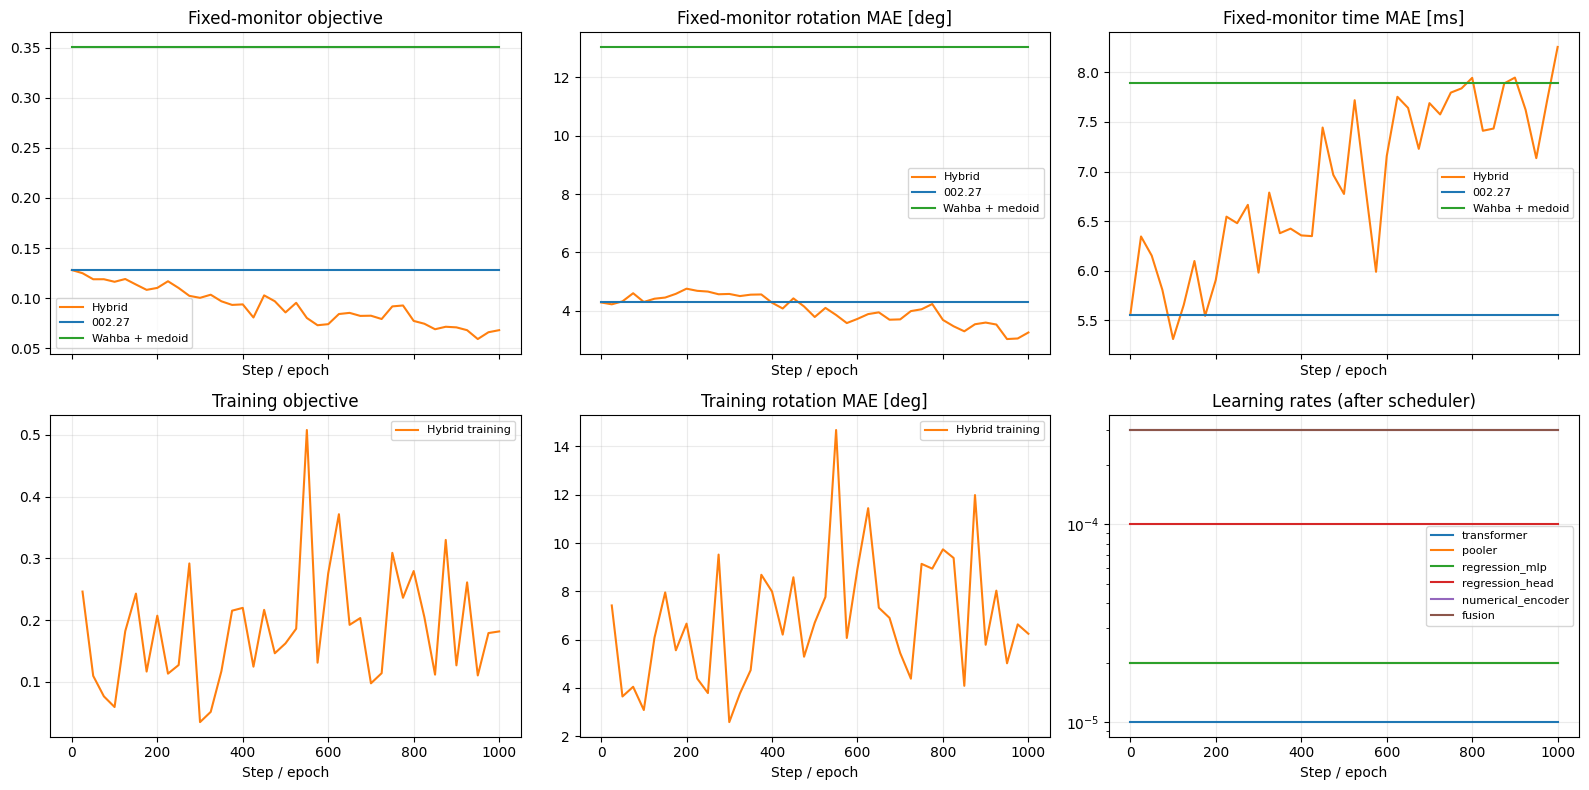

In [12]:

STOCHASTIC_BATCH_SIZE = BATCH_SIZE
STOCHASTIC_STEPS = 1000
STOCHASTIC_PRINT_EVERY = 25

stochastic_history=[]
if RUN_STOCHASTIC_TEST:
    model.load_state_dict(initial_state,strict=True)
    rng=np.random.default_rng(RANDOM_SEED+81)
    if STOCHASTIC_BATCH_SIZE>len(train_dataset): raise ValueError('Stochastic batch exceeds training dataset.')
    stochastic_indices=rng.choice(len(train_dataset),size=STOCHASTIC_BATCH_SIZE,replace=False)
    stochastic_raw=window_batch_to(collate_windows([train_dataset[int(i)] for i in stochastic_indices]),DEVICE,dtype=MODEL_DTYPE)
    (RUN_DIR/'stochastic_indices.json').write_text(json.dumps(stochastic_indices.tolist()))
    opt=make_optimizer(model); best=initial_monitor['Hybrid_loss']; val=initial_monitor
    stochastic_history.append(history_row(0,{},val,opt)); save_checkpoint(STOCHASTIC_BEST_PATH,model,opt,None,0,best,stochastic_history)
    log_line('Stochastic 0',{},val,opt,True)
    try:
        since=time.perf_counter()
        for step in range(1,STOCHASTIC_STEPS+1):
            physical=fixed_seeded_physical(stochastic_raw,TRAIN_AUG_SEED+90_000+step)
            cases=sample_fault_cases(STOCHASTIC_BATCH_SIZE,np.random.default_rng(RANDOM_SEED+90_000+step))
            train=train_case_batch(model,opt,physical,cases)
            del physical,cases
            if step%STOCHASTIC_PRINT_EVERY==0 or step==STOCHASTIC_STEPS:
                val=evaluate_monitor(model,monitor_bank); stochastic_history.append(history_row(step,train,val,opt))
                improved=val['Hybrid_loss']<best
                if improved:
                    best=val['Hybrid_loss']; save_checkpoint(STOCHASTIC_BEST_PATH,model,opt,None,step,best,stochastic_history)
                save_checkpoint(STOCHASTIC_LAST_PATH,model,opt,None,step,best,stochastic_history)
                save_history(stochastic_history,'stochastic_history.csv')
                log_line(f'Stochastic {step}/{STOCHASTIC_STEPS}',train,val,opt,improved,time.perf_counter()-since); since=time.perf_counter()
        if STOCHASTIC_STEPS==0: save_checkpoint(STOCHASTIC_LAST_PATH,model,opt,None,0,best,stochastic_history)
    finally:
        model.load_state_dict(initial_state,strict=True); model.zero_grad(set_to_none=True)
        del stochastic_raw,opt; clear_cuda()
    plot_history(stochastic_history,'stochastic_learning_curves.png')
else: print('Stochastic training skipped.')

## 10. Matched evaluation helpers
All three methods see identical physical windows and faults. Error metrics include every prediction, even numerical failures (identity fallback); validity is reported separately. Assessment and controlled plots use the same held-out window bank for both stochastic and full checkpoints. Each panel has exactly three method curves. Time-only Wahba is not a time solver, and its zero time correction is an explicit no-update baseline.

In [13]:
@torch.no_grad()
def matched_predictions(net,tokens,numerical):
    Cn,cn,valid=numerical_absolute(numerical)
    return {'Hybrid':stack_predictions(net(tokens,numerical_features=numerical)), '002.27':stack_predictions(baseline_model(tokens)), 'Wahba + medoid':(Cn,cn)},valid


def make_controlled_cases(index,rng,sweep):
    cases=[]
    for sensor in CALIBRATION_KEYS:
        for axis_id in range(SWEEP_AXIS_REPEATS if sweep=='rotation' else 1):
            axis=rng.normal(size=3); axis/=np.linalg.norm(axis)
            values=SWEEP_ANGLES_DEG if sweep=='rotation' else SWEEP_TIMES_MS
            for value in values:
                for sign in ((-1,1) if sweep=='time' and value else (1,)):
                    angle=value if sweep=='rotation' else 0.; tau=sign*value if sweep=='time' else 0.
                    cases.append(dict(source_row=0,physical_id=int(index),fault_count=int(value>0),fault_mode=sweep,selected_sensor=sensor,axis_id=axis_id,angle_deg=angle,injected_time_ms=abs(tau),rotations={k:angle if k==sensor else 0. for k in CALIBRATION_KEYS},tau_ms={k:tau if k==sensor else 0. for k in CALIBRATION_KEYS},axes={k:axis if k==sensor else np.zeros(3) for k in CALIBRATION_KEYS}))
    return cases


@torch.no_grad()
def evaluate_matched(net,dataset,indices,seed,controlled=None):
    net.eval(); baseline_model.eval(); rows=[]; case_id=0
    group_size=1 if controlled else max(1,BATCH_SIZE//10)
    for start in range(0,len(indices),group_size):
        group=indices[start:start+group_size]
        raw=window_batch_to(collate_windows([dataset[int(i)] for i in group]),DEVICE,dtype=MODEL_DTYPE)
        physical=fixed_seeded_physical(raw,seed+int(group[0])*1009)
        rng=np.random.default_rng(seed+int(group[0])*7919+97)
        cases=make_controlled_cases(group[0],rng,controlled) if controlled else sample_fault_cases(len(group),rng,exhaustive=True,original_indices=group)
        for offset in range(0,len(cases),BATCH_SIZE):
            mini=cases[offset:offset+BATCH_SIZE]
            tokens,numerical,targets=prepare_case_batch(physical,mini)
            preds,valid=matched_predictions(net,tokens,numerical)
            valid=valid.cpu().numpy(); raw_valid=numerical.valid.cpu().numpy()
            for name,(C,c) in preds.items():
                d={k:v.cpu().numpy() for k,v in residuals(C,c,targets).items()}
                for b,case in enumerate(mini):
                    for j,key in enumerate(CALIBRATION_KEYS):
                        rows.append(dict(method=name,case_id=case_id+b,physical_index=case['physical_id'],sensor=key,selected_sensor=case.get('selected_sensor',case.get('injected_keys',('none',))[0] if case['fault_count']==1 else 'none'),fault_count=case['fault_count'],fault_mode=case['fault_mode'],axis_id=case.get('axis_id',-1),angle_deg=case.get('angle_deg',max(case['rotations'].values())),injected_time_ms=case.get('injected_time_ms',max(abs(v) for v in case['tau_ms'].values())),true_rotation_deg=case['rotations'][key],true_tau_ms=case['tau_ms'][key],wahba_valid=bool(valid[b]),pair_valid=bool(raw_valid[b,j]),**{k:float(v[b,j]) for k,v in d.items()}))
            case_id+=len(mini)
            del tokens,numerical,targets,preds,d
        del raw,physical,cases
    df=pd.DataFrame(rows)
    assert len(df) and not df.duplicated(['method','case_id','sensor']).any()
    assert df.groupby(['case_id','sensor']).size().eq(3).all()
    return df


def fault_counts(truth,alarm):
    truth=np.asarray(truth,dtype=bool); alarm=np.asarray(alarm,dtype=bool)
    tp=int((truth&alarm).sum()); fp=int((~truth&alarm).sum()); fn=int((truth&~alarm).sum()); tn=int((~truth&~alarm).sum())
    return dict(tp=tp,fp=fp,fn=fn,tn=tn,f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else np.nan,recall=tp/(tp+fn) if tp+fn else np.nan,precision=tp/(tp+fp) if tp+fp else np.nan,accuracy=(tp+tn)/len(truth))


def summarize_assessment(df):
    rows=[]
    for label,subset in [('K0/K1',df[df.fault_count<=1]),('all K',df)]:
        for name,g in subset.groupby('method',sort=False):
            r=fault_counts(g.true_rotation_deg>GT_ROT_TOL_DEG,g.correction>GT_ROT_TOL_DEG)
            t=fault_counts(g.true_tau_ms.abs()>GT_TAU_TOL_MS,g.time_correction>GT_TAU_TOL_MS)
            j=fault_counts((g.true_rotation_deg>GT_ROT_TOL_DEG)|(g.true_tau_ms.abs()>GT_TAU_TOL_MS),(g.correction>GT_ROT_TOL_DEG)|(g.time_correction>GT_TAU_TOL_MS))
            rows.append(dict(group=label,method=name,n_cases=g.case_id.nunique(),rotation_mae=g.rotation.mean(),rotation_p90=g.rotation.quantile(.9),relative_mae=g.loc[g.sensor!=REFERENCE_KEY,'relative'].mean(),time_mae=g.time.mean(),rotation_f1=r['f1'],rotation_recall=r['recall'],time_f1=t['f1'],time_recall=t['recall'],joint_f1=j['f1'],wahba_valid=g.wahba_valid.mean()))
    return pd.DataFrame(rows)


def plot_controlled(df,sweep,prefix):
    x='angle_deg' if sweep=='rotation' else 'injected_time_ms'
    err='rotation' if sweep=='rotation' else 'time'
    pred='correction' if sweep=='rotation' else 'time_correction'
    truth='true_rotation_deg' if sweep=='rotation' else 'true_tau_ms'
    tol=GT_ROT_TOL_DEG if sweep=='rotation' else GT_TAU_TOL_MS
    unit='deg' if sweep=='rotation' else 'ms'; summaries=[]
    fig,axes=plt.subplots(3,4,figsize=(19,11),squeeze=False)
    for row,sensor in enumerate(CALIBRATION_KEYS):
        subset=df[df.selected_sensor==sensor]
        for name in METHODS:
            g=subset[subset.method==name]; records=[]
            for value,h in g.groupby(x):
                selected=h[h.sensor==sensor]; healthy=h[h.sensor!=sensor]
                f=fault_counts(h[truth].abs()>tol,h[pred]>tol)
                records.append(dict(method=name,sensor=sensor,magnitude=value,n_cases=selected.case_id.nunique(),correction_median=selected[pred].median(),residual_median=selected[err].median(),residual_p90=selected[err].quantile(.9),healthy_p90=healthy[err].quantile(.9),valid_rate=selected.wahba_valid.mean(),**f))
            s=pd.DataFrame(records); summaries.append(s)
            for col,field in enumerate(('correction_median','residual_median','healthy_p90','f1')):
                axes[row,col].plot(s.magnitude,s[field],'-o',label=name,color=METHOD_COLORS[name],markersize=3)
        # Reference thresholds only (no extra method curves).
        axes[row,1].axhline(tol,color='gray',ls=':',alpha=.6); axes[row,2].axhline(tol,color='gray',ls=':',alpha=.6); axes[row,3].set_ylim(0,1.03)
        for col,title in enumerate(('Predicted absolute correction','Remaining absolute error','Healthy-head error P90','Fault micro-F1')):
            ax=axes[row,col]; ax.set(title=f'{sensor} | {title}',xlabel=f'Initial {sweep} error [{unit}]',ylabel='F1' if col==3 else unit); ax.grid(alpha=.25)
            if row==0: ax.legend(fontsize=8)
    fig.suptitle(f'{prefix} | matched K=1 {sweep} sweep | medians unless P90 stated')
    finish_figure(fig,f'{prefix}_{sweep}_comparison.png')
    pd.concat(summaries,ignore_index=True).to_csv(RUN_DIR/f'{prefix}_{sweep}_summary.csv',index=False)


def assess_checkpoint(path,prefix,dataset,indices,seed,*,sweeps=True):
    state=load_checkpoint(path,model); step=state['step']; del state
    print(f'{prefix}: {path.name}, step={step}, {len(indices)} held-out physical windows',flush=True)
    df=evaluate_matched(model,dataset,indices,seed)
    df.to_csv(RUN_DIR/f'{prefix}_assessment_raw.csv',index=False)
    summary=summarize_assessment(df); summary.to_csv(RUN_DIR/f'{prefix}_assessment.csv',index=False); display(summary.round(3))
    if sweeps:
        for sweep in ('rotation','time'):
            d=evaluate_matched(model,dataset,indices,seed+900,controlled=sweep)
            d.to_csv(RUN_DIR/f'{prefix}_{sweep}_raw.csv',index=False); plot_controlled(d,sweep,prefix); del d
    clear_cuda()
    return summary

## 11. Independent stochastic assessment
Evaluate the best stochastic checkpoint, not the monitor. The final stochastic checkpoint is retained separately and can be evaluated by changing the path. Full training resets from the original weights regardless of this evaluation.

stochastic_best_validation: stochastic_best.pt, step=950, 48 held-out physical windows


,group,method,n_cases,rotation_mae,rotation_p90,relative_mae,time_mae,rotation_f1,rotation_recall,time_f1,time_recall,joint_f1,wahba_valid
0,K0/K1,Hybrid,192,4.996,6.663,9.274,6.863,0.724,0.797,0.558,0.857,0.642,1.0
1,K0/K1,002.27,192,4.513,4.856,8.432,5.964,0.731,0.826,0.574,0.810,0.703,1.0
2,K0/K1,Wahba + medoid,192,16.735,53.110,26.334,8.760,0.296,0.870,0.000,0.000,0.405,1.0
3,all K,Hybrid,480,11.540,32.439,21.090,11.309,0.671,0.617,0.710,0.771,0.768,1.0
4,all K,002.27,480,11.437,21.424,19.867,14.045,0.678,0.599,0.618,0.596,0.709,1.0
5,all K,Wahba + medoid,480,22.509,88.685,29.256,23.071,0.465,0.746,0.000,0.000,0.613,1.0


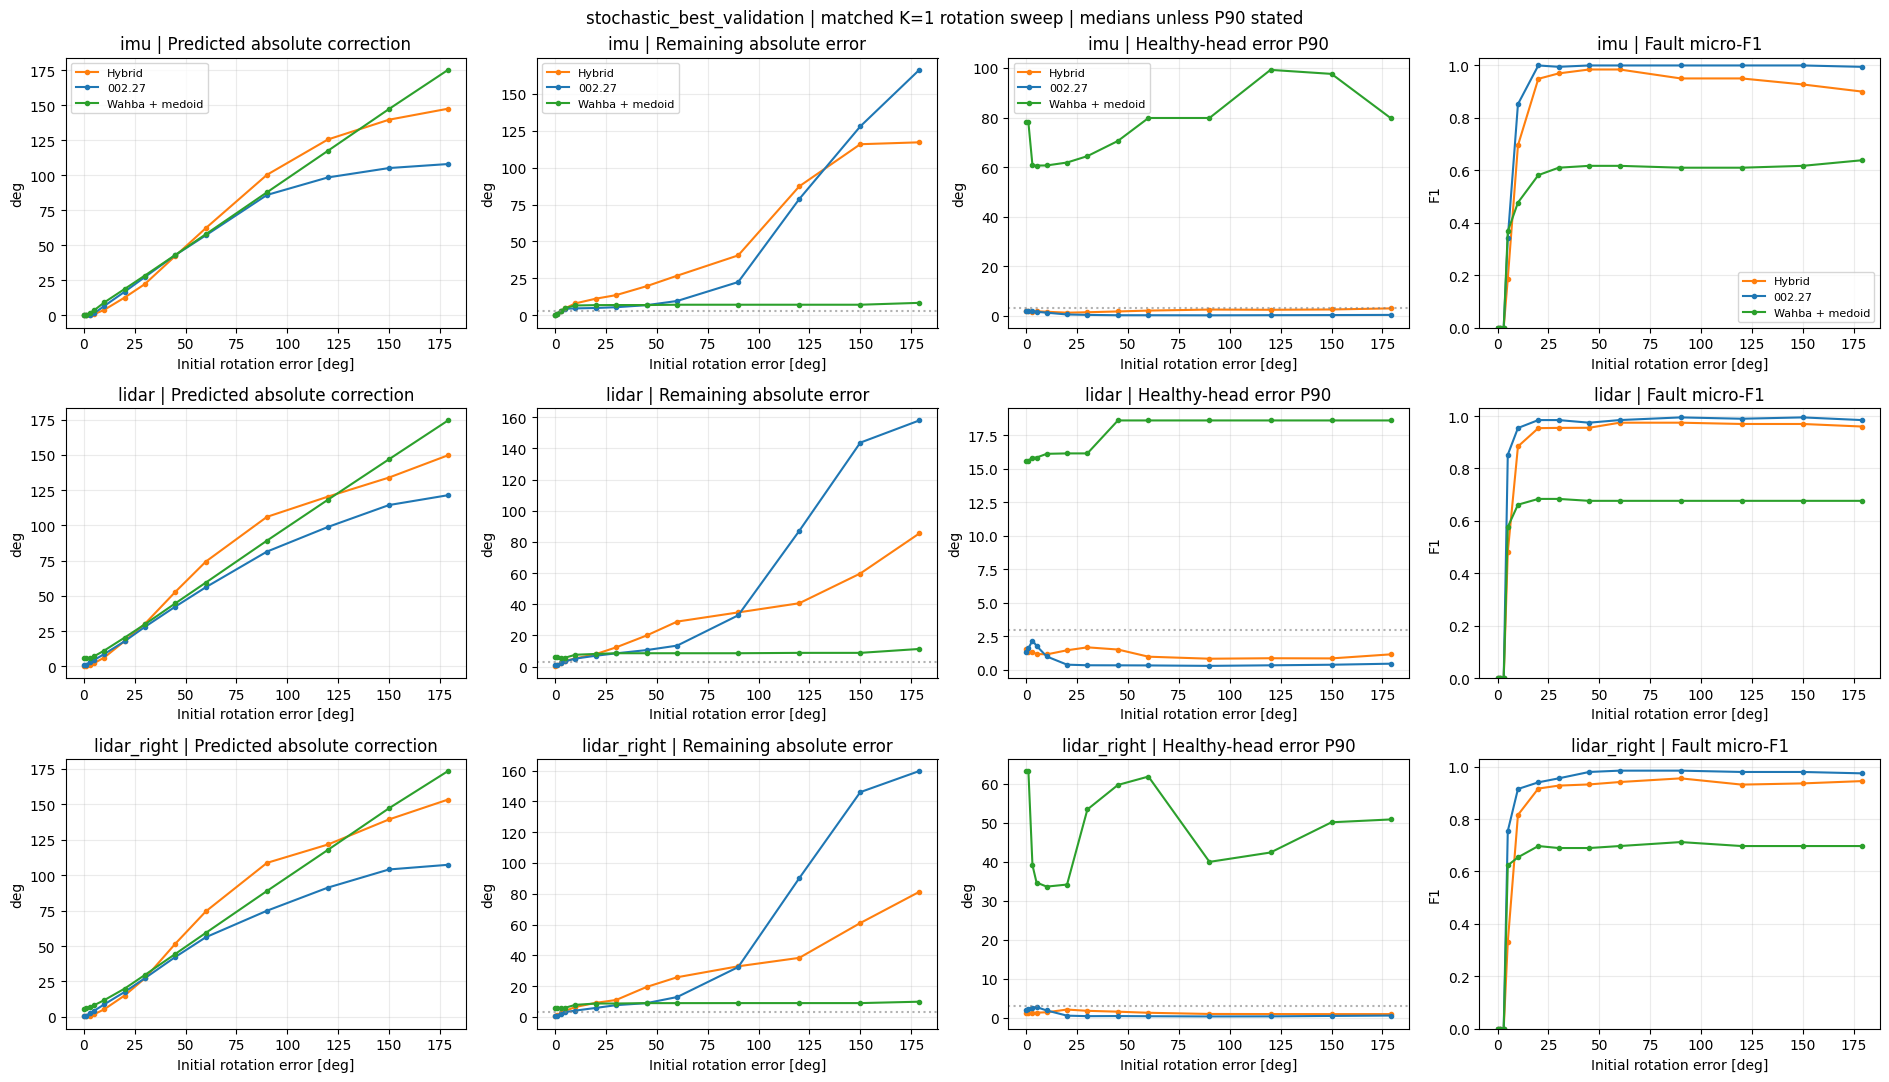

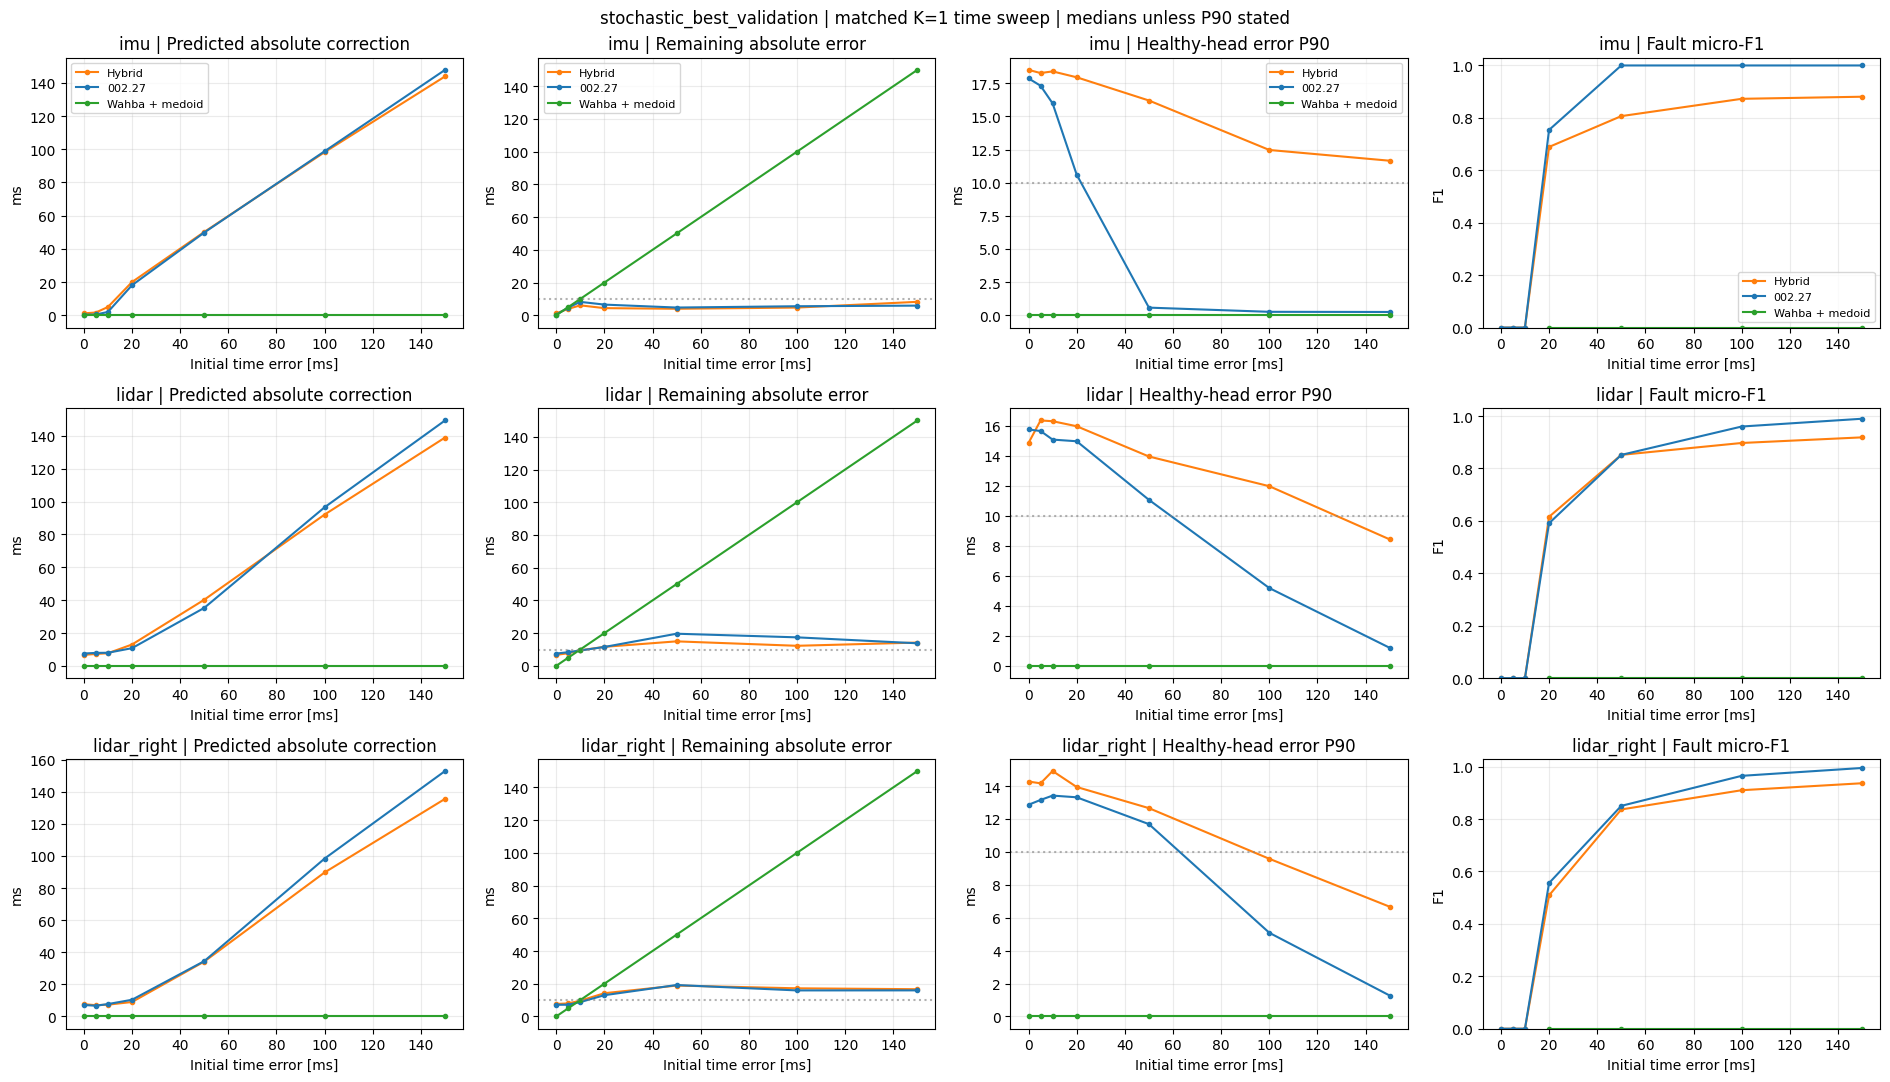

In [14]:
if RUN_STOCHASTIC_TEST:
    stochastic_summary=assess_checkpoint(STOCHASTIC_BEST_PATH,'stochastic_best_validation',val_dataset,assessment_val_indices,VALIDATION_AUG_SEED+99)
    model.load_state_dict(initial_state,strict=True); clear_cuda()

## 12. Full training
Only one compact line per completed epoch, including elapsed time, training/validation objective, rotation/time MAE for the three methods and all current LRs. `RESUME_TRAINING=True` continues from the last completed epoch; increase `NUM_EPOCHS` if needed. Set `RUN_STOCHASTIC_TEST=False` on resume to skip the unrelated diagnostic. Interrupting an unfinished epoch leaves its preceding checkpoint intact.

Epoch 0 | val=0.1280 | Hybrid: 4.28°/5.56ms 002.27: 4.28°/5.56ms Wahba + medoid: 13.05°/7.89ms | LR transformer=1.00e-05 pooler=2.00e-05 regression_mlp=2.00e-05 regression_head=1.00e-04 numerical_encoder=3.00e-04 fusion=3.00e-04 | best
Epoch 1/200 | train=0.2636 | val=0.1182 | Hybrid: 4.55°/4.63ms 002.27: 4.28°/5.56ms Wahba + medoid: 13.05°/7.89ms | LR transformer=1.00e-05 pooler=2.00e-05 regression_mlp=2.00e-05 regression_head=1.00e-04 numerical_encoder=3.00e-04 fusion=3.00e-04 | best | 121.0s
Epoch 2/200 | train=0.2475 | val=0.1146 | Hybrid: 4.30°/6.24ms 002.27: 4.28°/5.56ms Wahba + medoid: 13.05°/7.89ms | LR transformer=1.00e-05 pooler=2.00e-05 regression_mlp=2.00e-05 regression_head=1.00e-04 numerical_encoder=3.00e-04 fusion=3.00e-04 | best | 120.6s
Epoch 3/200 | train=0.2551 | val=0.1066 | Hybrid: 4.48°/5.29ms 002.27: 4.28°/5.56ms Wahba + medoid: 13.05°/7.89ms | LR transformer=1.00e-05 pooler=2.00e-05 regression_mlp=2.00e-05 regression_head=1.00e-04 numerical_encoder=3.00e-04 fusi

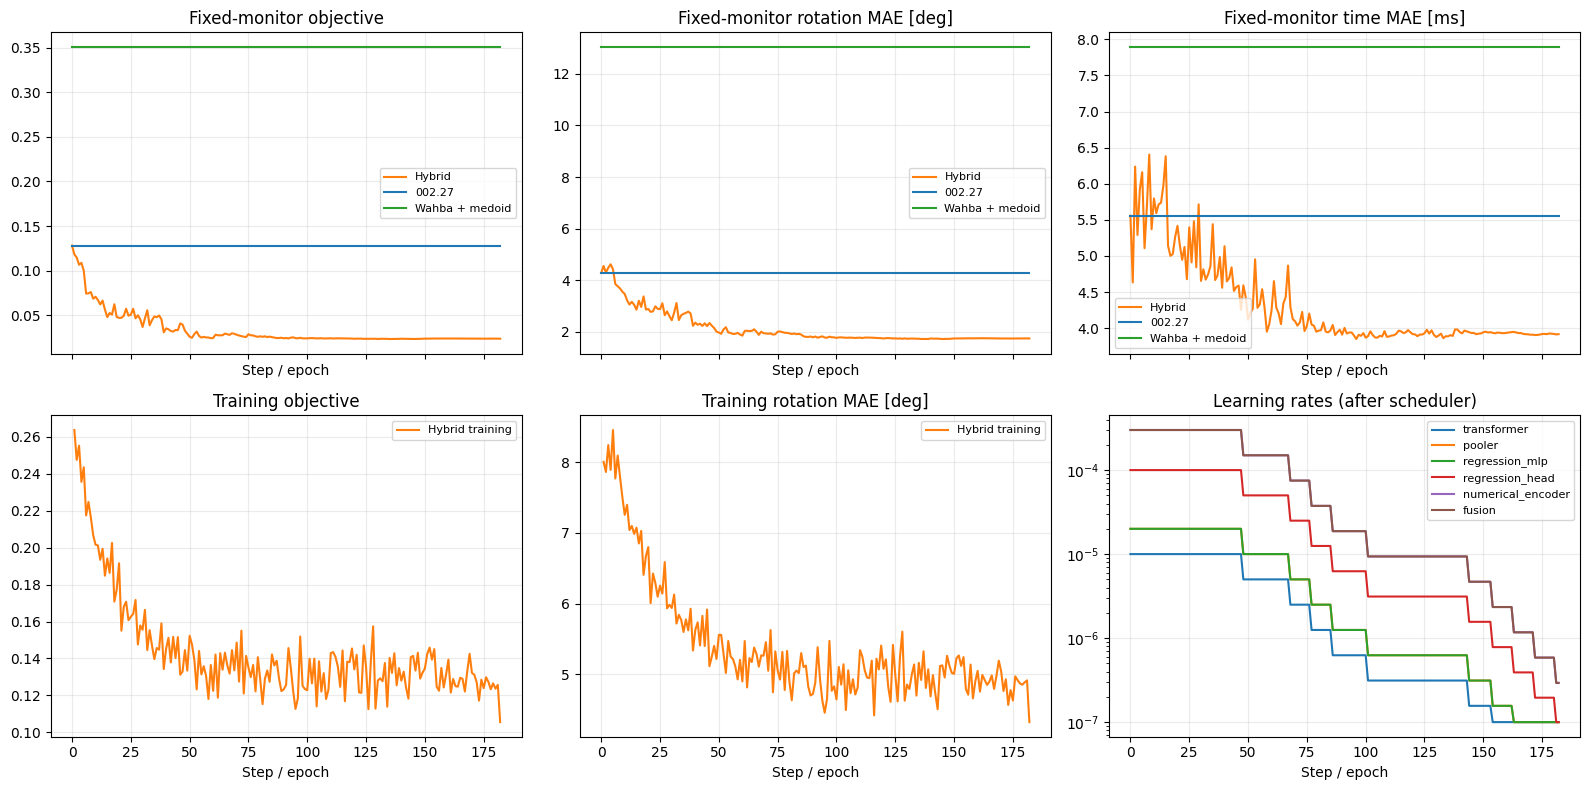

In [15]:
training_history=[]
if RUN_FULL_TRAINING:
    model.load_state_dict(initial_state,strict=True); optimizer=make_optimizer(model)
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=LR_REDUCTION_FACTOR,patience=LR_PATIENCE_EPOCHS,min_lr=MIN_LR)
    start_epoch=0; best=initial_monitor['Hybrid_loss']
    if RESUME_TRAINING:
        state=load_checkpoint(LAST_CHECKPOINT_PATH,model)
        optimizer.load_state_dict(state['optimizer_state_dict']); scheduler.load_state_dict(state['scheduler_state_dict'])
        start_epoch=int(state['step']); best=float(state['best']); training_history=state['history']
        train_shuffle_generator.set_state(state['train_shuffle_state']); torch.set_rng_state(state['torch_rng_state'])
        if DEVICE.type=='cuda' and state['cuda_rng_state']: torch.cuda.set_rng_state_all(state['cuda_rng_state'])
        del state
    else:
        if BEST_CHECKPOINT_PATH.exists() or LAST_CHECKPOINT_PATH.exists(): raise FileExistsError('Full-run checkpoint exists. Change RUN_NAME or set RESUME_TRAINING=True.')
        train_shuffle_generator.manual_seed(RANDOM_SEED+25); torch.manual_seed(RANDOM_SEED+89)
        if DEVICE.type=='cuda': torch.cuda.manual_seed_all(RANDOM_SEED+89)
        training_history.append(history_row(0,{},initial_monitor,optimizer))
        save_checkpoint(BEST_CHECKPOINT_PATH,model,optimizer,scheduler,0,best,training_history)
        save_checkpoint(LAST_CHECKPOINT_PATH,model,optimizer,scheduler,0,best,training_history)
        save_history(training_history,'training_history.csv'); log_line('Epoch 0',{},initial_monitor,optimizer,True)
    try:
        for epoch in range(start_epoch,NUM_EPOCHS):
            start=time.perf_counter(); train=run_train_epoch(model,optimizer,epoch)
            val=evaluate_monitor(model,monitor_bank); scheduler.step(val['Hybrid_loss'])
            training_history.append(history_row(epoch+1,train,val,optimizer))
            improved=val['Hybrid_loss']<best
            if improved:
                best=val['Hybrid_loss']; save_checkpoint(BEST_CHECKPOINT_PATH,model,optimizer,scheduler,epoch+1,best,training_history)
            save_checkpoint(LAST_CHECKPOINT_PATH,model,optimizer,scheduler,epoch+1,best,training_history)
            save_history(training_history,'training_history.csv')
            log_line(f'Epoch {epoch+1}/{NUM_EPOCHS}',train,val,optimizer,improved,time.perf_counter()-start)
            clear_cuda()
    except KeyboardInterrupt:
        print('Interrupted. Use saved best/last; unfinished epoch was not committed.')
    finally:
        model.zero_grad(set_to_none=True); del optimizer,scheduler; clear_cuda()
    plot_history(training_history,'full_training_learning_curves.png')
else:
    print('Full training skipped; existing checkpoints can still be evaluated.')
    if (RUN_DIR/'training_history.csv').exists():
        training_history=pd.read_csv(RUN_DIR/'training_history.csv').to_dict('records'); plot_history(training_history,'full_training_learning_curves.png')

## 13. Full-run evaluation
Change `EVALUATION_CHECKPOINT` to `LAST_CHECKPOINT_PATH` to evaluate the final rather than best model. By default this uses held-out validation physical windows; optional untouched test split is separate. A numerical ablation is reported as a scalar table, not a fourth curve.

validation_best: best.pt, step=145, 48 held-out physical windows


,group,method,n_cases,rotation_mae,rotation_p90,relative_mae,time_mae,rotation_f1,rotation_recall,time_f1,time_recall,joint_f1,wahba_valid
0,K0/K1,Hybrid,192,3.115,3.518,6.360,3.934,0.819,0.754,0.756,0.810,0.797,1.0
1,K0/K1,002.27,192,4.513,4.856,8.432,5.964,0.731,0.826,0.574,0.810,0.703,1.0
2,K0/K1,Wahba + medoid,192,16.735,53.110,26.334,8.760,0.296,0.870,0.000,0.000,0.405,1.0
3,all K,Hybrid,480,8.172,15.875,15.255,7.911,0.720,0.602,0.809,0.784,0.825,1.0
4,all K,002.27,480,11.437,21.424,19.867,14.045,0.678,0.599,0.618,0.596,0.709,1.0
5,all K,Wahba + medoid,480,22.509,88.685,29.256,23.071,0.465,0.746,0.000,0.000,0.613,1.0


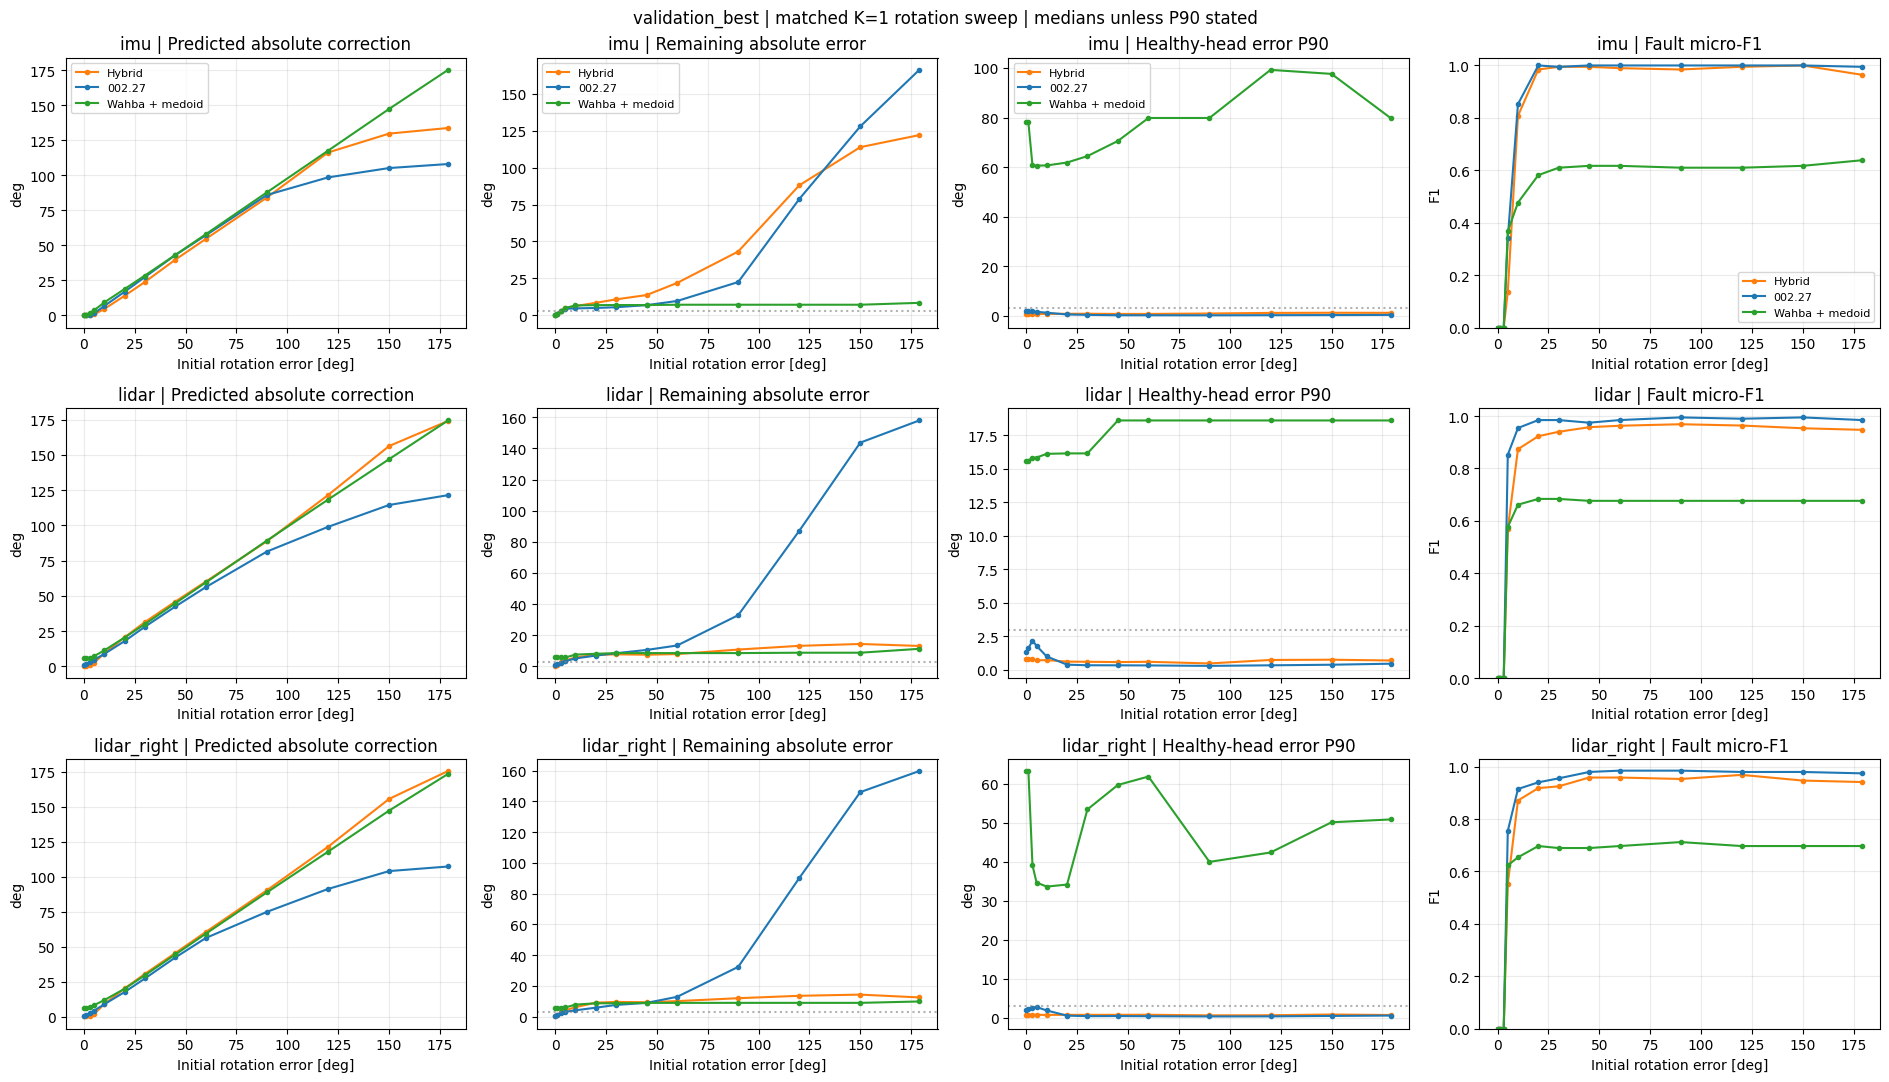

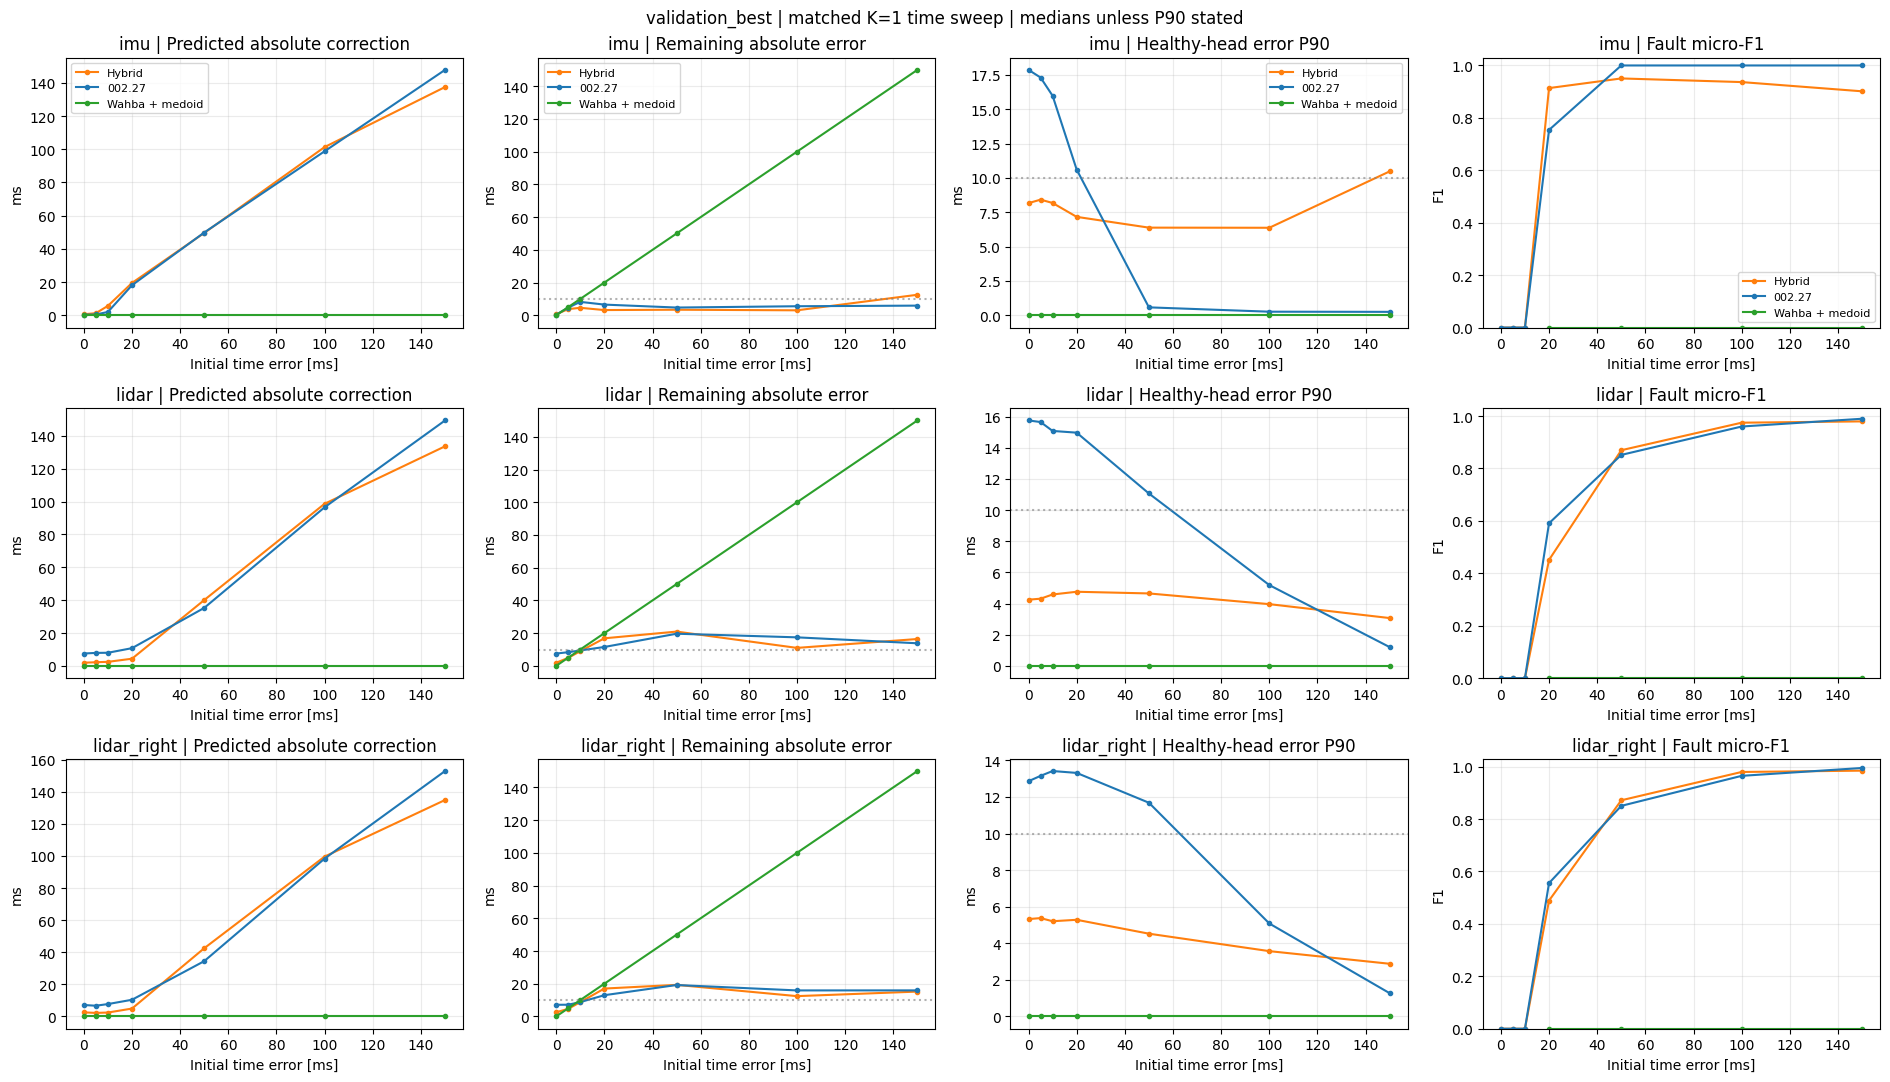

,rotation_mae,time_mae
numerical_enabled,,
False,4.402,4.384
True,1.723,3.934


In [16]:
EVALUATION_CHECKPOINT=BEST_CHECKPOINT_PATH
if EVAL_SPLIT=='validation':
    eval_dataset,eval_names,eval_indices,eval_seed=val_dataset,VAL_NAMES,assessment_val_indices,VALIDATION_AUG_SEED+99
else:
    eval_dataset,eval_names,eval_indices,eval_seed=test_dataset,TEST_NAMES,assessment_indices(test_dataset,TEST_NAMES),TEST_AUG_SEED+99
if RUN_DETAILED_EVALUATION:
    full_summary=assess_checkpoint(EVALUATION_CHECKPOINT,f'{EVAL_SPLIT}_{EVALUATION_CHECKPOINT.stem}',eval_dataset,eval_indices,eval_seed)
    # Same fixed validation monitor: disabling the numerical embedding is a targeted ablation,
    # not a fourth comparison method and not a replacement for held-out accuracy.
    with torch.no_grad():
        vals=[]; model.eval()
        for tokens,num,targets,_,_,valid in monitor_bank:
            for enabled in (True,False):
                C,c=stack_predictions(model(tokens,numerical_features=num,use_numerical=enabled)); d=residuals(C,c,targets)
                vals.append(dict(numerical_enabled=enabled,n=len(valid),rotation_sum=float(d['rotation'].sum()),time_sum=float(d['time'].sum())))
        ablation=pd.DataFrame(vals).groupby('numerical_enabled').sum(); ablation['rotation_mae']=ablation.rotation_sum/(3*ablation.n); ablation['time_mae']=ablation.time_sum/(3*ablation.n)
        display(ablation[['rotation_mae','time_mae']].round(3)); ablation.to_csv(RUN_DIR/'validation_monitor_ablation.csv')

## 14. Chronological rotation rollouts (evaluation only)
Use the same initial perturbations, same chronological windows, fixed physical calibration over each trajectory, and model-specific evolving priors. The numerical features are recomputed after every update. Apply all three absolute rotation corrections. Default: hold time fixed, so these are pure rotation rollouts. This is not the independent single-window assessment bank; the rollout starts span each sequence and may overlap monitoring windows. Report median CTG, correction magnitude, and healthy sensor P90. Numerical validity failures count as no update.

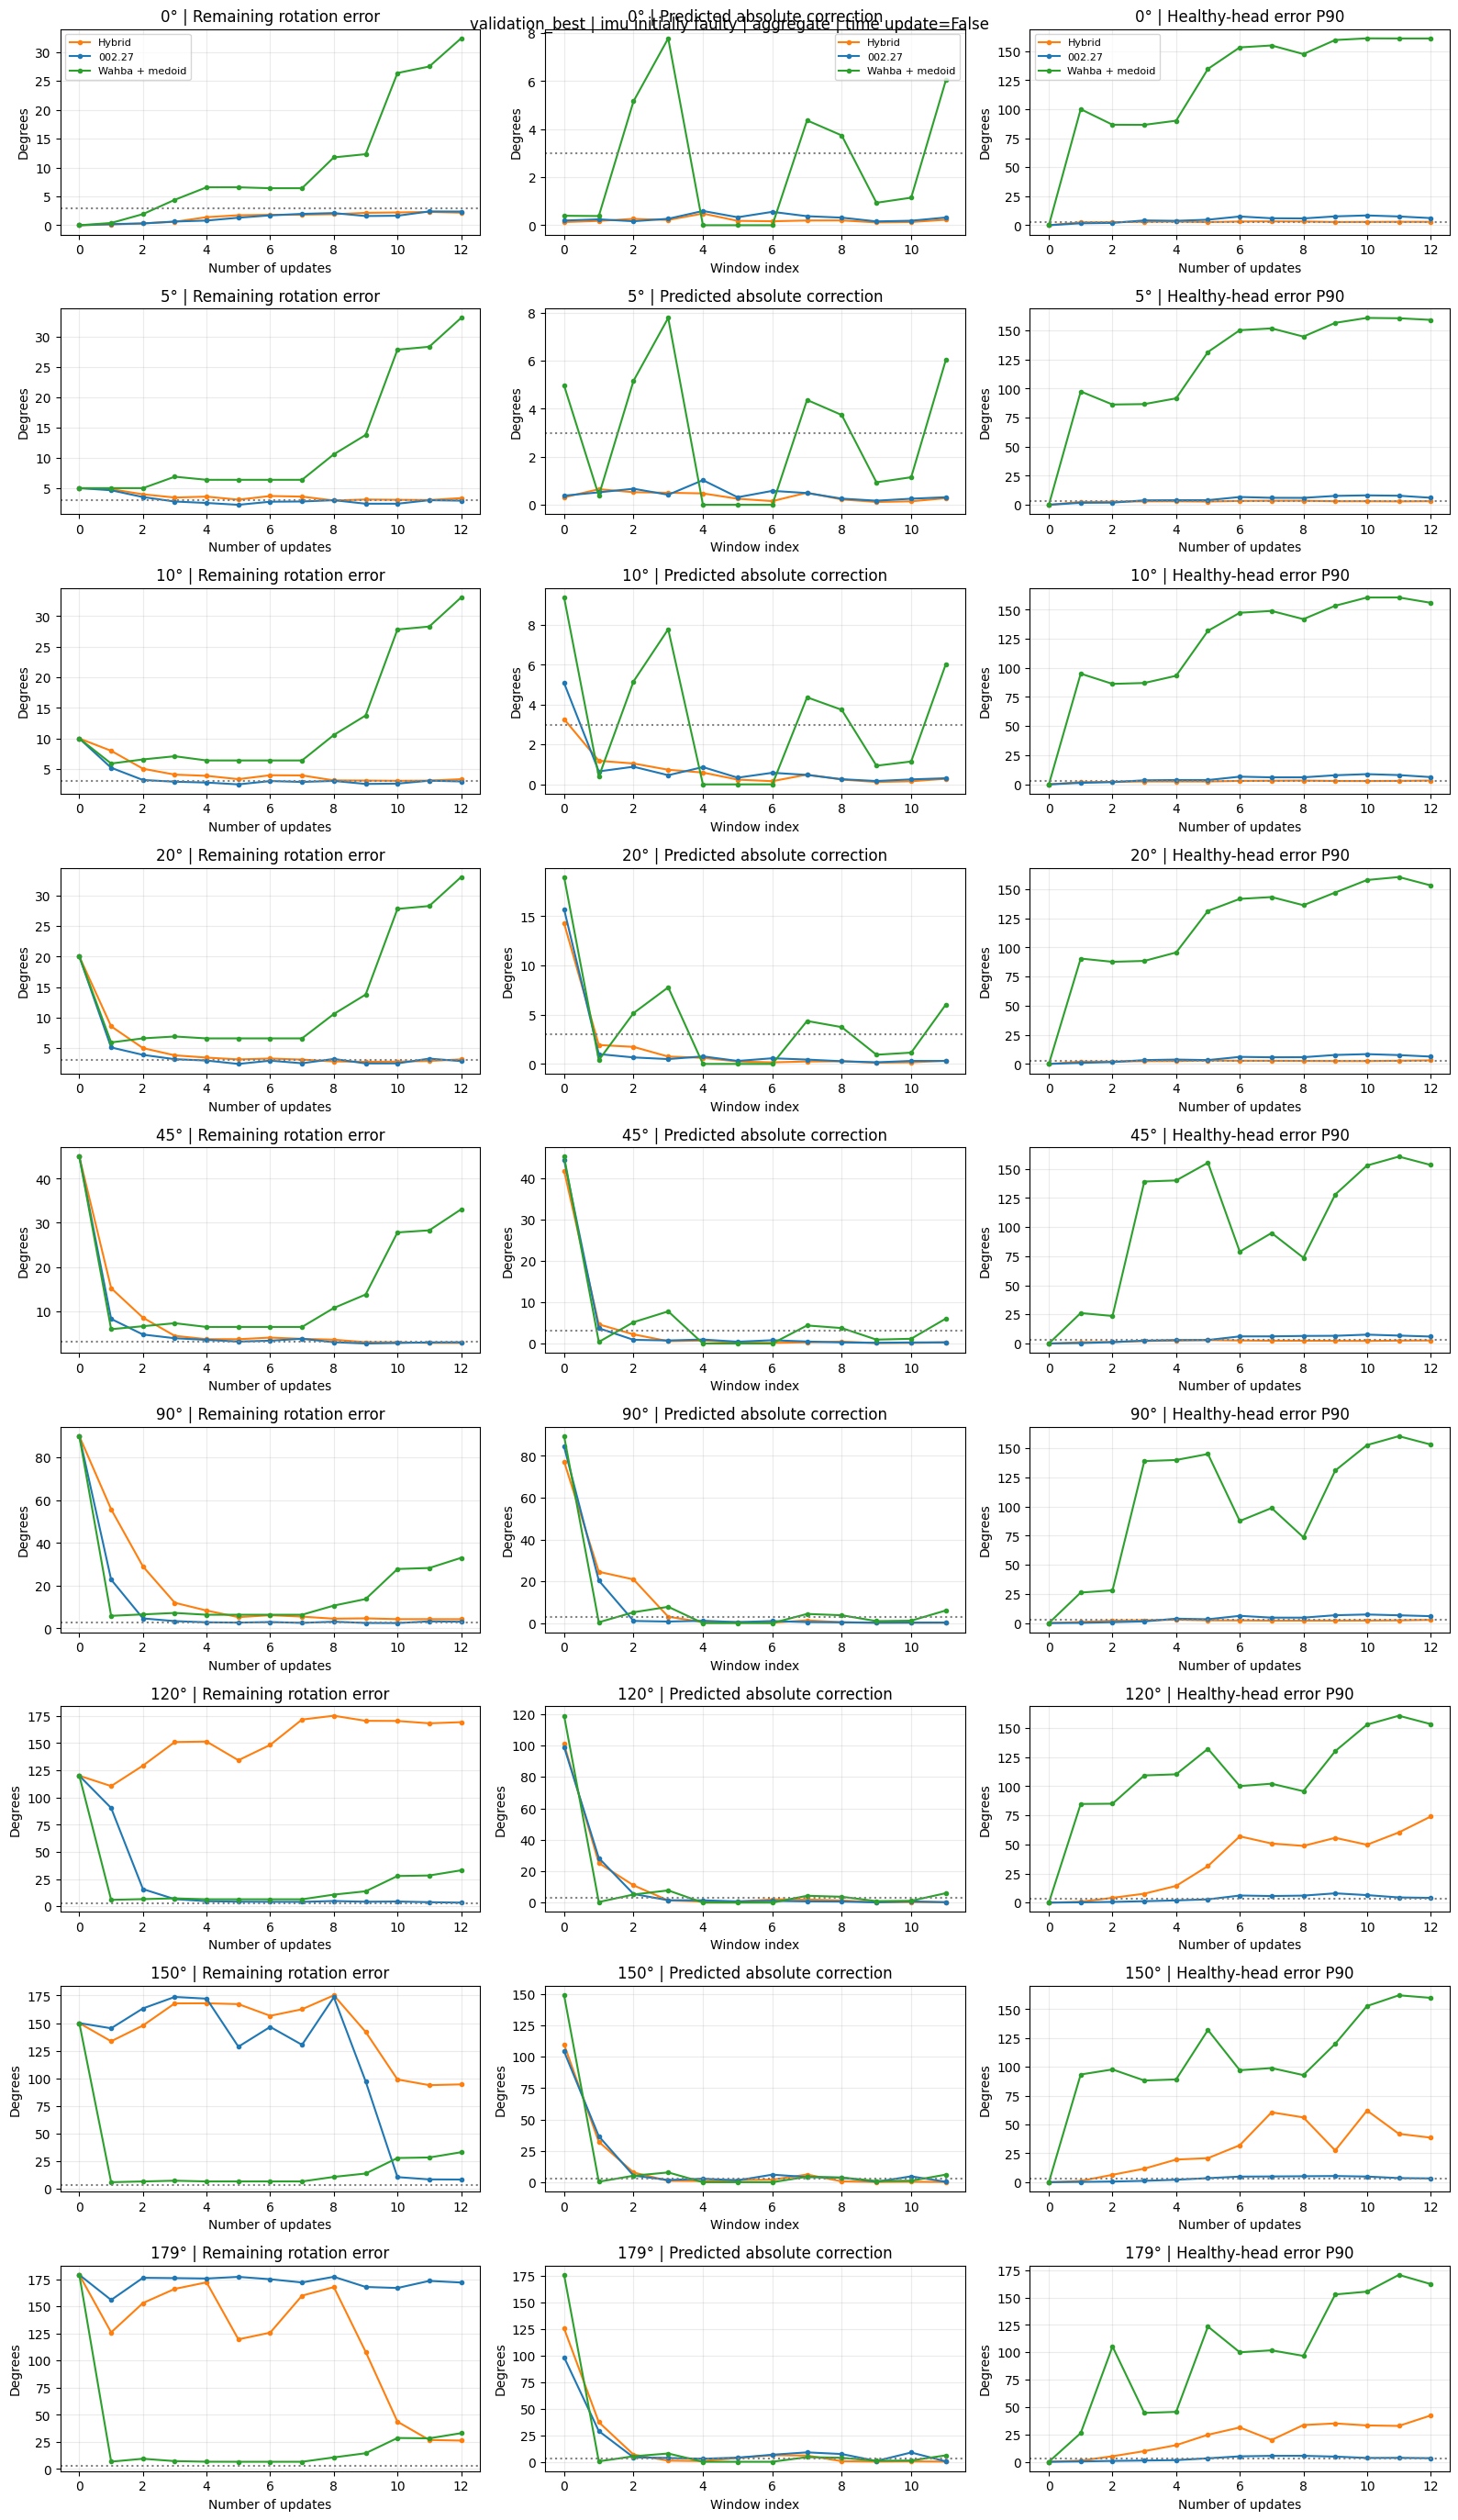

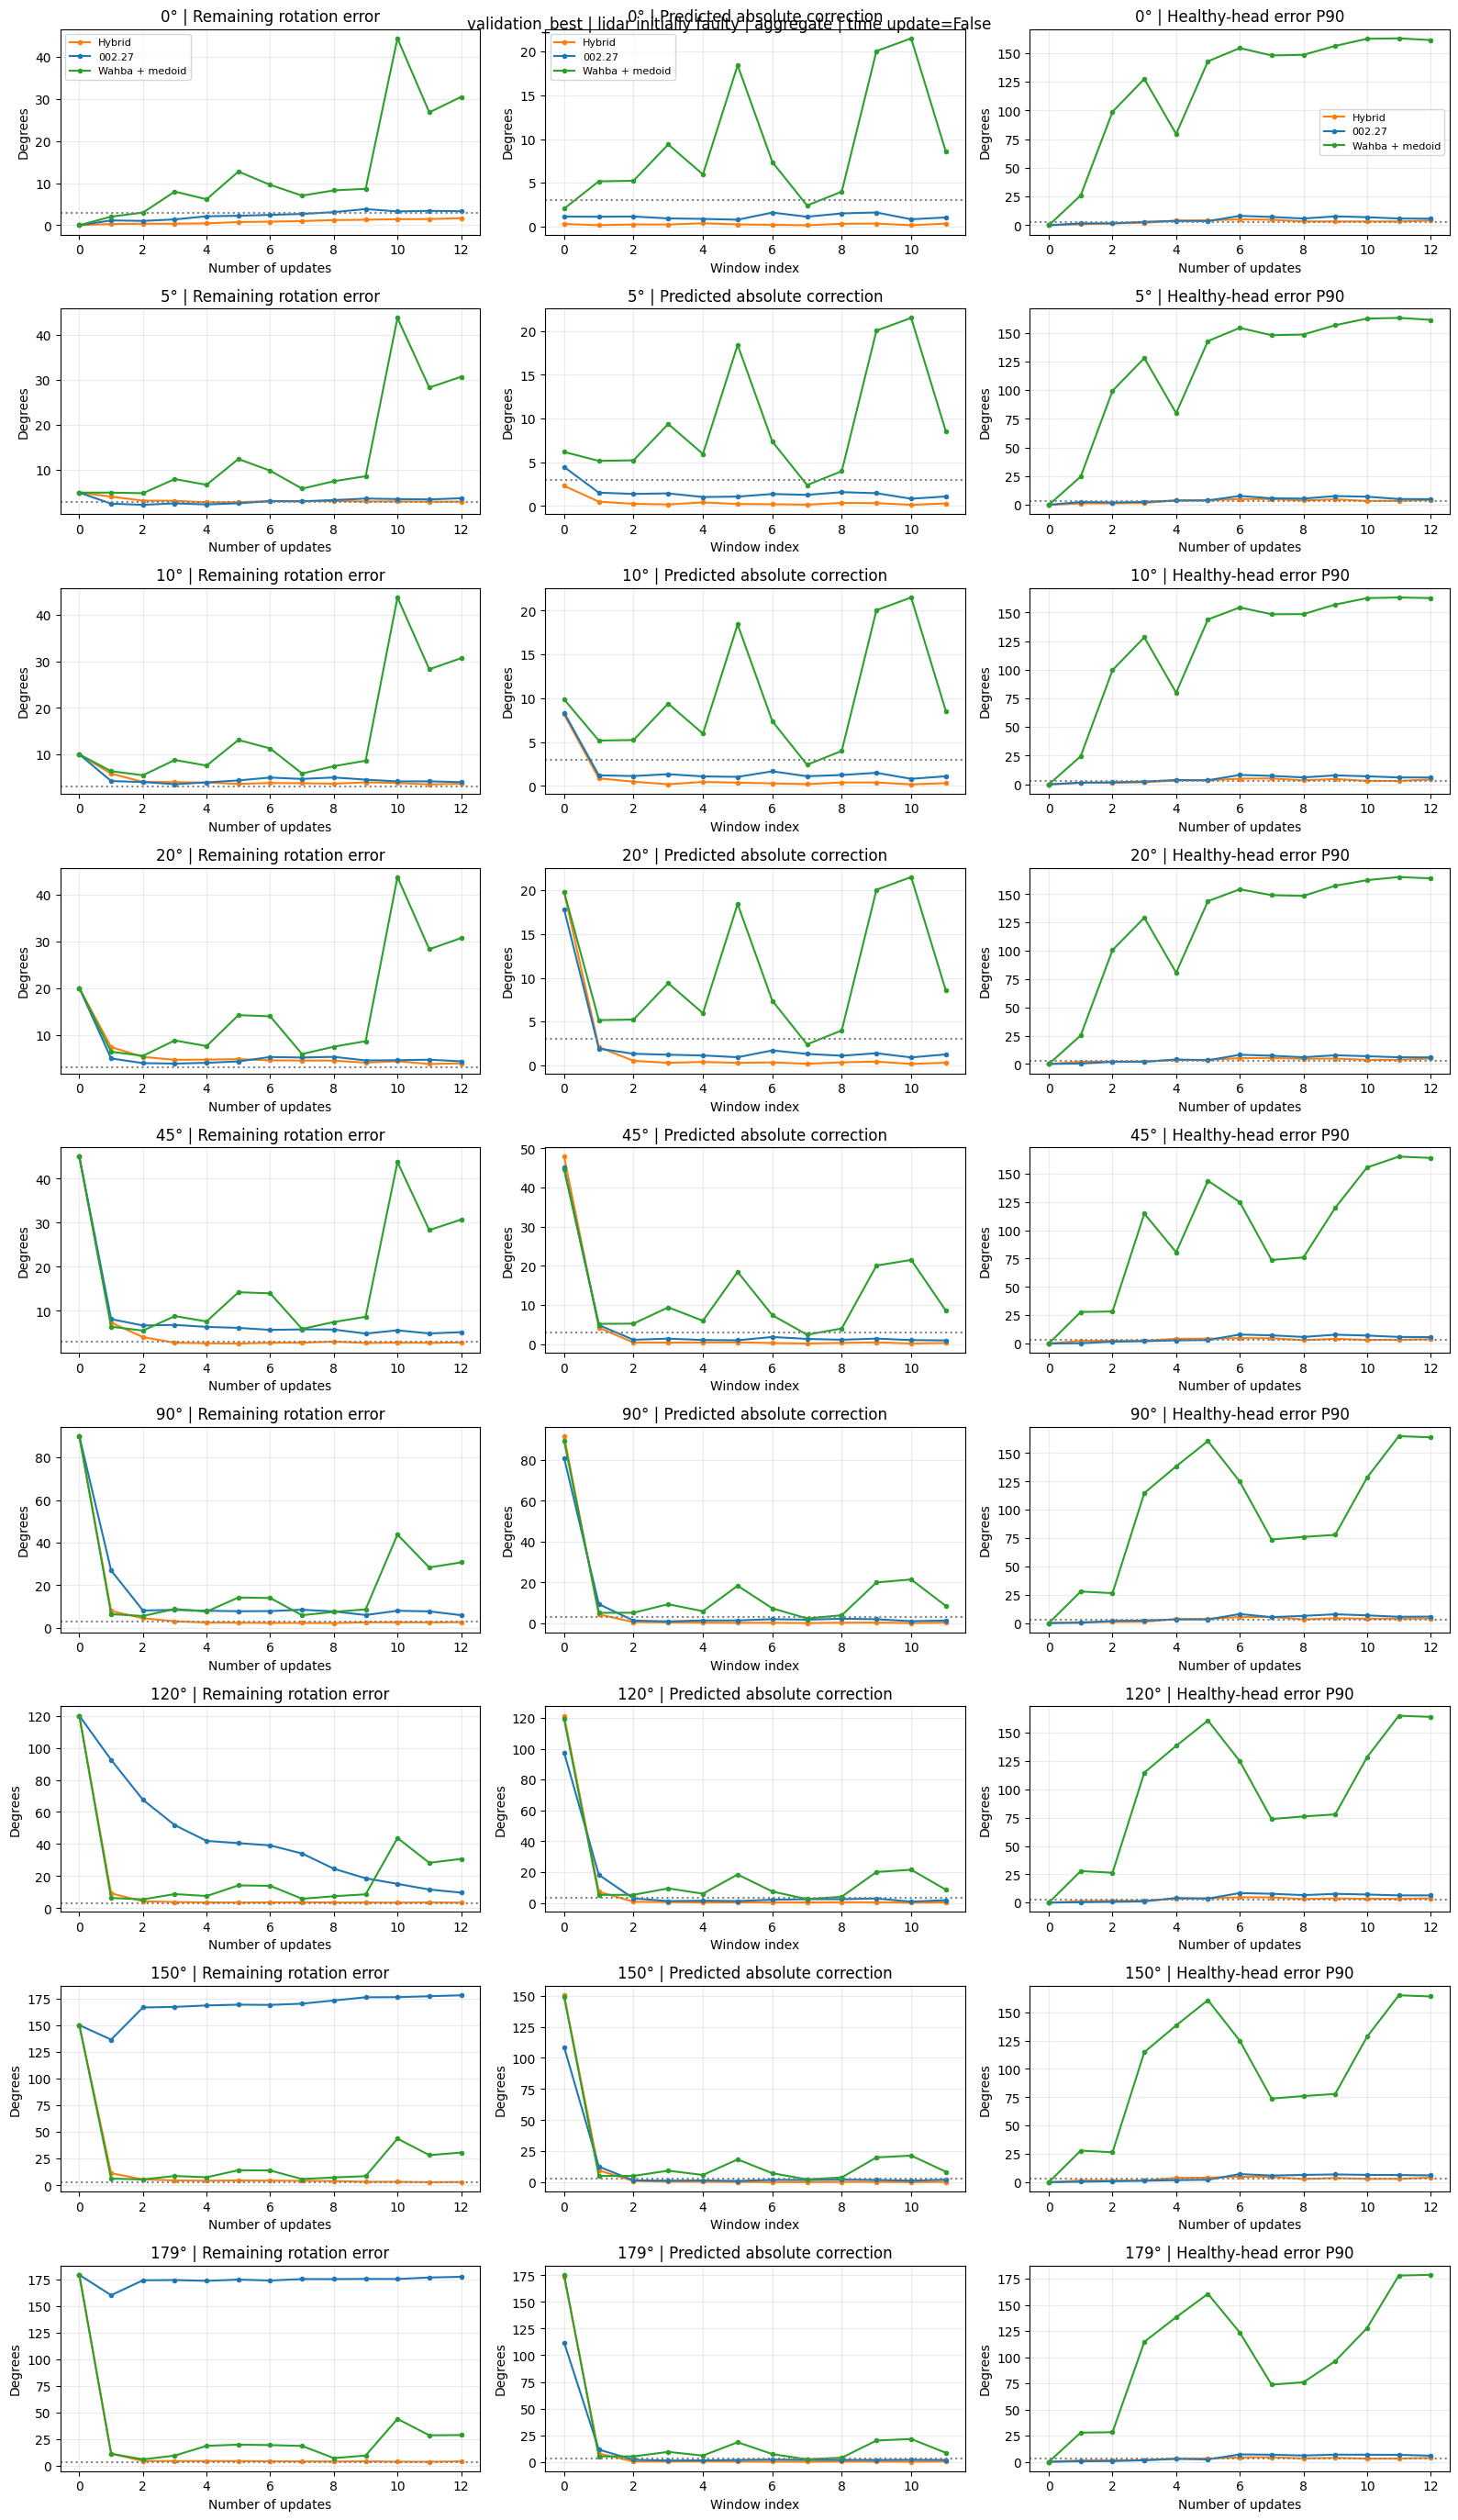

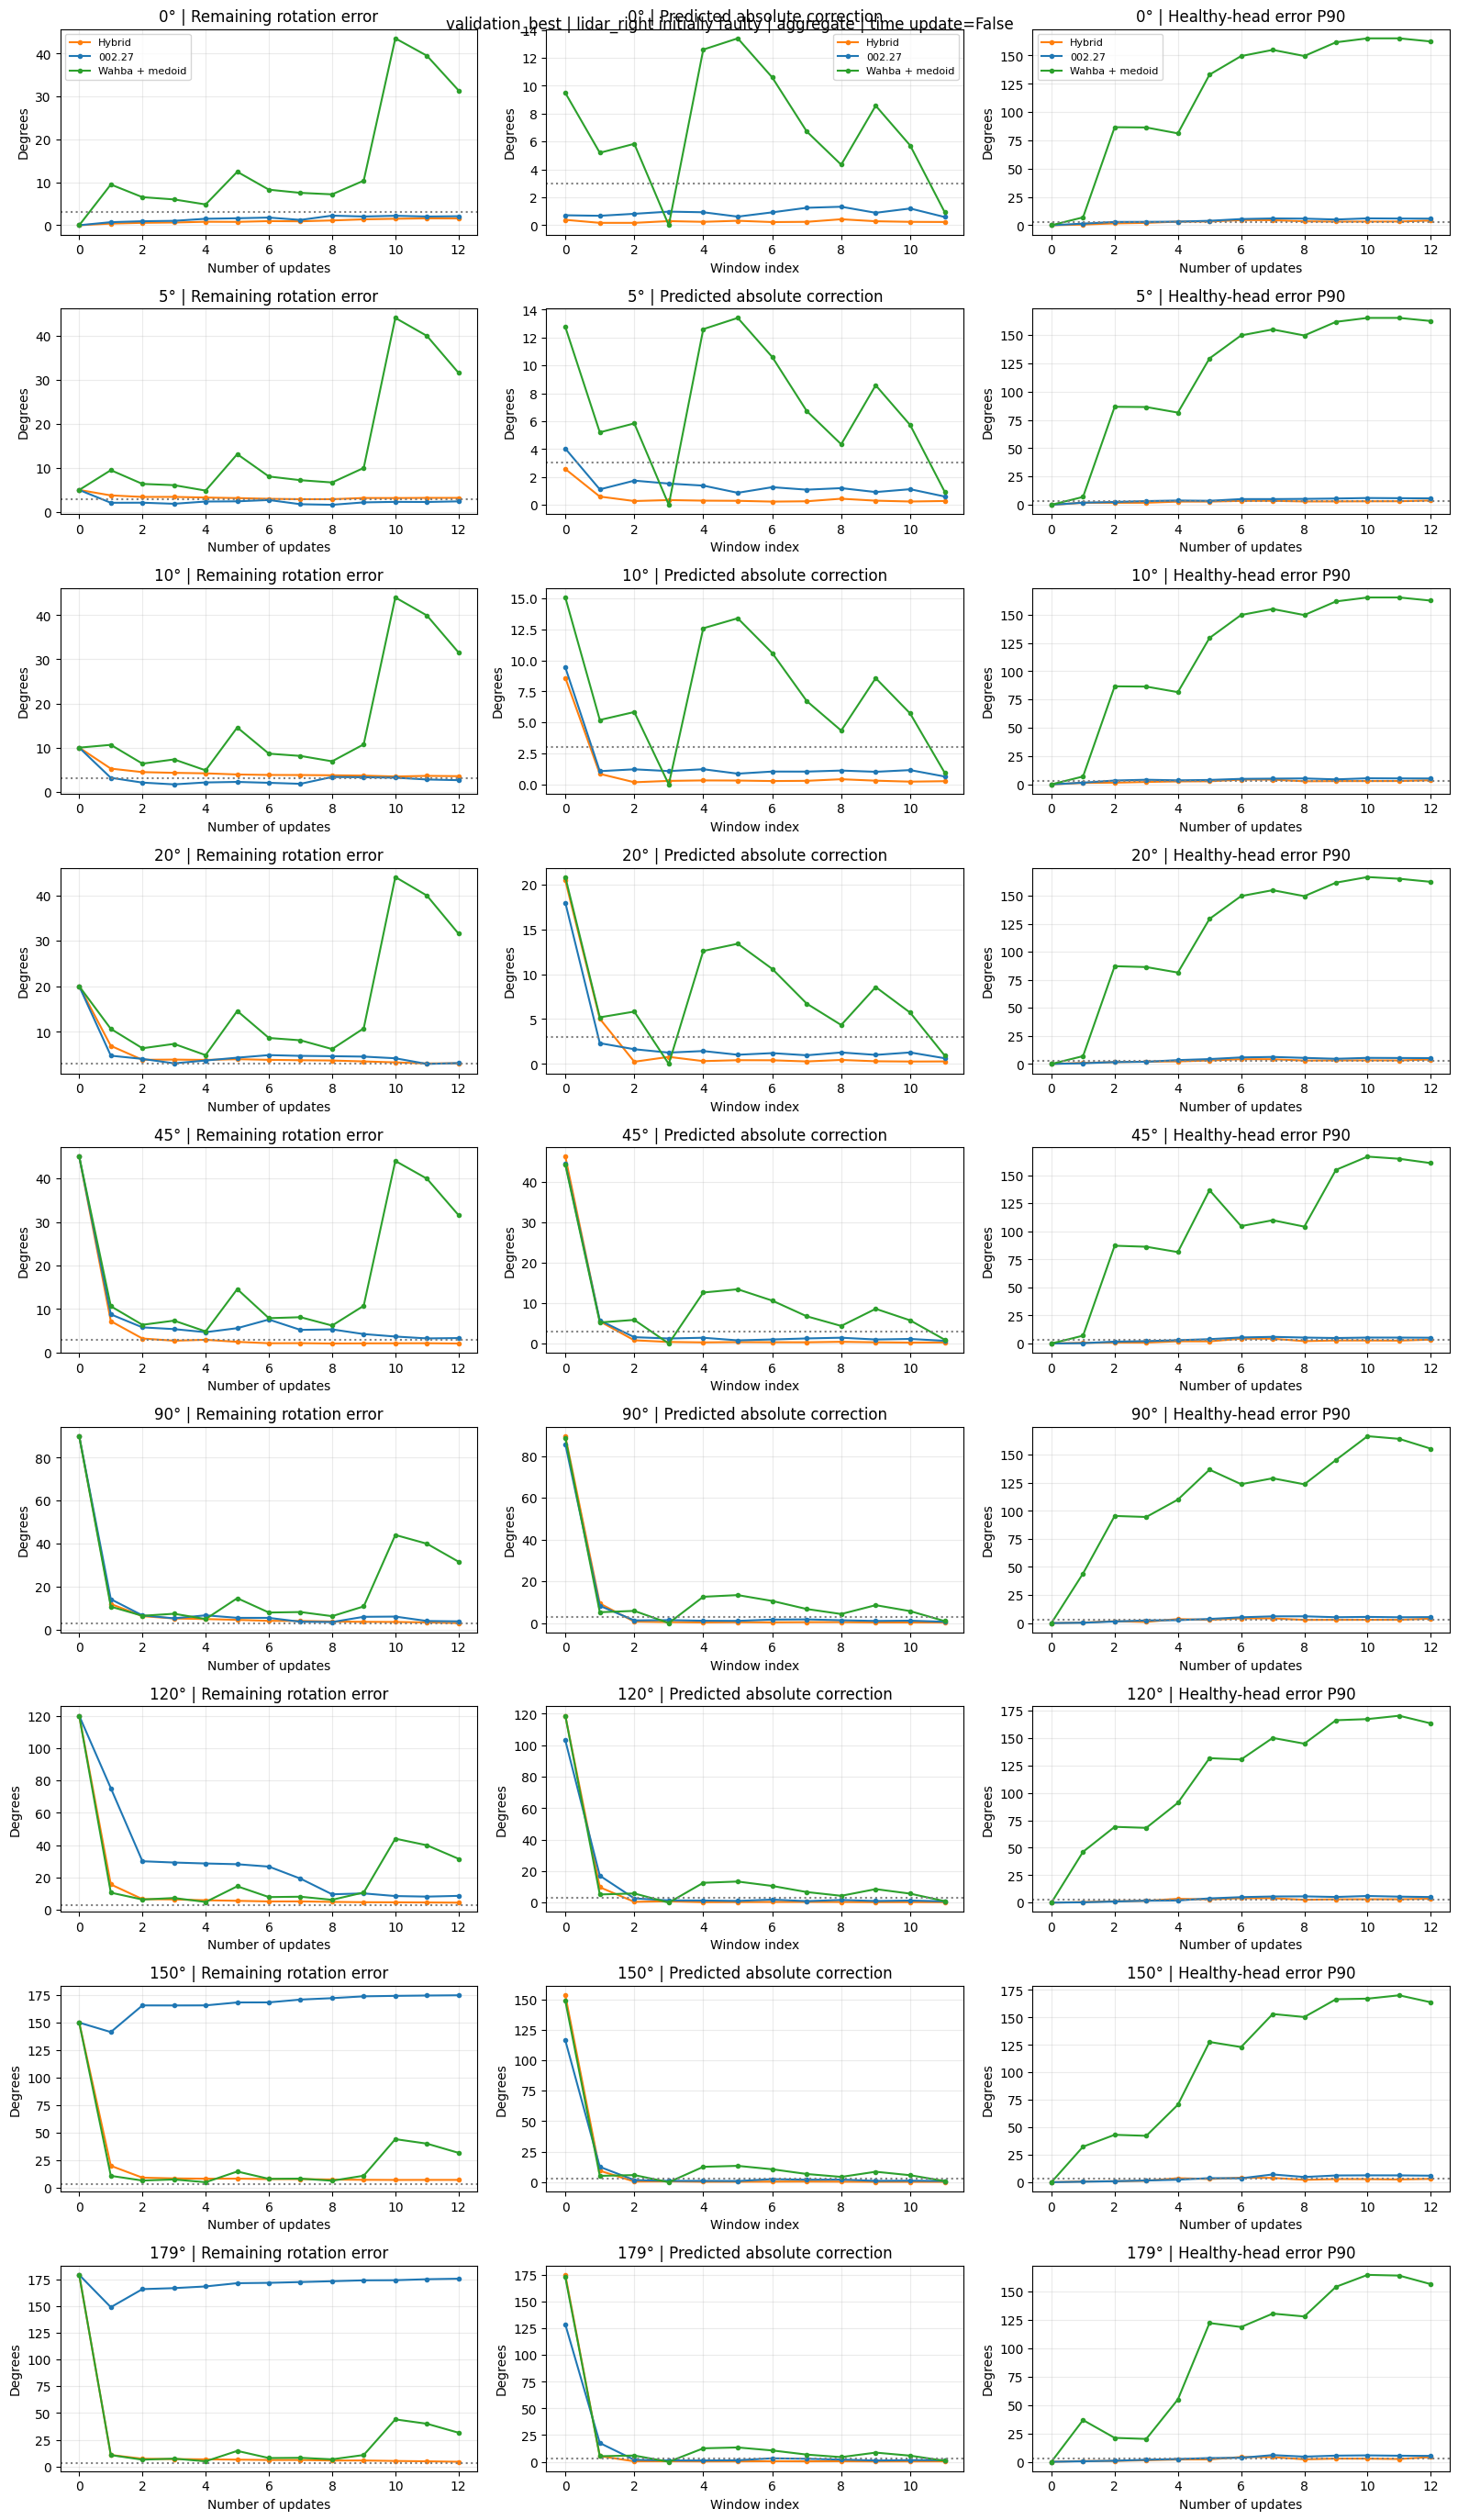

,selected_sensor,angle_deg,method,n,final_median_deg,final_mean_deg,final_p90_deg,success_rate
0,imu,0.0,002.27,16,2.367,2.641,4.915,0.500
1,imu,0.0,Hybrid,16,2.173,2.653,4.772,0.625
2,imu,0.0,Wahba + medoid,16,32.368,71.883,162.786,0.000
3,imu,5.0,002.27,16,2.935,2.962,4.906,0.500
4,imu,5.0,Hybrid,16,3.354,3.387,5.145,0.375
...,...,...,...,...,...,...,...,...
76,lidar_right,150.0,Hybrid,16,6.943,7.944,14.846,0.250
77,lidar_right,150.0,Wahba + medoid,16,31.559,62.123,161.002,0.000
78,lidar_right,179.0,002.27,16,175.413,143.278,178.157,0.062
79,lidar_right,179.0,Hybrid,16,4.419,8.556,19.589,0.438


In [17]:
@torch.no_grad()
def rollout_evaluation(net,dataset,names,seed):
    net.eval(); baseline_model.eval(); rows=[]
    for seq_id,seq in enumerate(names):
        available=np.asarray(dataset.window_indices_for_sequence(seq),dtype=int)
        max_start=len(available)-ROLLOUT_WINDOWS
        if max_start<0: raise ValueError(f'{seq}: insufficient windows for rollout')
        starts=np.unique(np.linspace(0,max_start,min(ROLLOUT_STARTS_PER_SEQUENCE,max_start+1)).round().astype(int))
        for start in starts:
            indices=available[start:start+ROLLOUT_WINDOWS]
            physical_seed=seed+500_000+seq_id*100_003+int(start)*1009
            windows=[]
            for index in indices:
                raw=window_batch_to(collate_windows([dataset[int(index)]]),DEVICE,dtype=MODEL_DTYPE)
                windows.append(fixed_seeded_physical(raw,physical_seed))
            truth=windows[0].current_calibration
            for w in windows[1:]:
                for key in CALIBRATION_KEYS:
                    torch.testing.assert_close(w.current_calibration[key].transform,truth[key].transform,atol=3e-5,rtol=3e-5)
                    torch.testing.assert_close(w.current_calibration[key].time_offset,truth[key].time_offset,atol=3e-6,rtol=3e-6)
            rng=np.random.default_rng(physical_seed+51); cases=[]
            for sensor in CALIBRATION_KEYS:
                for axis_id in range(SWEEP_AXIS_REPEATS):
                    axis=rng.normal(size=3); axis/=np.linalg.norm(axis)
                    for angle in ROLLOUT_ANGLES_DEG:
                        cases.append(dict(source_row=0,selected_sensor=sensor,angle_deg=angle,axis_id=axis_id,rotations={k:angle if k==sensor else 0. for k in CALIBRATION_KEYS},tau_ms={k:0. for k in CALIBRATION_KEYS},axes={k:axis if k==sensor else np.zeros(3) for k in CALIBRATION_KEYS}))
            for offset in range(0,len(cases),BATCH_SIZE):
                mini=cases[offset:offset+BATCH_SIZE]
                initial=faulted_window_from_cases(windows[0],mini).current_calibration
                for name in METHODS:
                    states=initial
                    for step,physical in enumerate(windows):
                        # Repeated raw streams from this chronological window, never reinject a fault.
                        repeated=faulted_window_from_cases(physical,mini)
                        window=WindowBatch(streams=dict(repeated.streams),current_calibration=states,metadata=dict(repeated.metadata),targets=None,dataset_indices=None)
                        streams=geometry_processor(window.streams,window.metadata,states)
                        valid=torch.ones(len(mini),dtype=torch.bool,device=DEVICE)
                        if name=='002.27':
                            tokens=tokenizer(streams,calibration_keys=CALIBRATION_KEYS); C,c=stack_predictions(baseline_model(tokens))
                        else:
                            num=numerical_extractor(streams,CALIBRATION_KEYS,raw_streams=window.streams)
                            if name=='Hybrid':
                                tokens=tokenizer(streams,calibration_keys=CALIBRATION_KEYS); C,c=stack_predictions(net(tokens,numerical_features=num)); valid=num.valid[:,1:].all(1)
                            else: C,c,valid=numerical_absolute(num)
                        targets=correction_targets(physical,window,mini); d=residuals(C,c,targets)
                        pre=distance_so3_deg(targets[0],targets[1]); applied_time=c if ROLLOUT_UPDATE_TIME else torch.zeros_like(c)
                        new_states={}
                        for j,key in enumerate(CALIBRATION_KEYS):
                            state=states[key]; T=state.transform.clone(); T[:,:3,:3]=C[:,j]@T[:,:3,:3]
                            new_states[key]=CalibrationState(transform=T,time_offset=state.time_offset+(applied_time[:,j]*1e-3).reshape_as(state.time_offset))
                        arrays={k:v.cpu().numpy() for k,v in dict(pre=pre,rotation=d['rotation'],correction=d['correction'],time=(applied_time-targets[3]).abs()).items()}; valid_np=valid.cpu().numpy()
                        for b,case in enumerate(mini):
                            for j,key in enumerate(CALIBRATION_KEYS):
                                rows.append(dict(method=name,sequence=seq,start_index=int(indices[0]),selected_sensor=case['selected_sensor'],angle_deg=case['angle_deg'],axis_id=case['axis_id'],step=step,sensor=key,wahba_valid=bool(valid_np[b]) if name!='002.27' else np.nan,**{k:float(v[b,j]) for k,v in arrays.items()}))
                        states=new_states
            del windows
    df=pd.DataFrame(rows)
    assert len(df) and not df.duplicated(['method','sequence','start_index','selected_sensor','angle_deg','axis_id','step','sensor']).any()
    assert df.groupby(['sequence','start_index','selected_sensor','angle_deg','axis_id','step','sensor']).size().eq(3).all()
    return df


def plot_rollouts(df,prefix,example=None):
    # example=None means aggregate; otherwise (sequence,start_index,axis_id).
    if example is not None:
        seq,start,axis_id=example; df=df[(df.sequence==seq)&(df.start_index==start)&(df.axis_id==axis_id)]
        if df.empty: raise ValueError('Requested rollout not found')
    for sensor in CALIBRATION_KEYS:
        fig,axes=plt.subplots(len(ROLLOUT_ANGLES_DEG),3,figsize=(16,3.1*len(ROLLOUT_ANGLES_DEG)),squeeze=False)
        for i,angle in enumerate(ROLLOUT_ANGLES_DEG):
            subset=df[(df.selected_sensor==sensor)&(df.angle_deg==angle)]
            for name in METHODS:
                g=subset[subset.method==name]; selected=g[g.sensor==sensor]; healthy=g[g.sensor!=sensor]
                initial=selected[selected.step==0].pre.median(); residual=selected.groupby('step').rotation.median(); correction=selected.groupby('step').correction.median(); hp=healthy.groupby('step').rotation.quantile(.9)
                axes[i,0].plot(np.r_[0,residual.index+1],np.r_[initial,residual],'-o',markersize=3,label=name,color=METHOD_COLORS[name])
                axes[i,1].plot(correction.index,correction,'-o',markersize=3,label=name,color=METHOD_COLORS[name])
                axes[i,2].plot(np.r_[0,hp.index+1],np.r_[0.,hp],'-o',markersize=3,label=name,color=METHOD_COLORS[name])
            for col,title in enumerate(('Remaining rotation error','Predicted absolute correction','Healthy-head error P90')):
                ax=axes[i,col]; ax.axhline(GT_ROT_TOL_DEG,ls=':',color='gray'); ax.set(title=f'{angle:g}° | {title}',xlabel='Window index' if col==1 else 'Number of updates',ylabel='Degrees'); ax.grid(alpha=.25)
                if i==0: ax.legend(fontsize=8)
        fig.suptitle(f'{prefix} | {sensor} initially faulty | {"aggregate" if example is None else example} | time update={ROLLOUT_UPDATE_TIME}')
        finish_figure(fig,f'{prefix}_rollout_{sensor}_{"aggregate" if example is None else "individual"}.png')

if RUN_ROLLOUT_EVALUATION:
    state=load_checkpoint(EVALUATION_CHECKPOINT,model); del state
    prefix=f'{EVAL_SPLIT}_{EVALUATION_CHECKPOINT.stem}'
    rollout_df=rollout_evaluation(model,eval_dataset,eval_names,eval_seed)
    rollout_df.to_csv(RUN_DIR/f'{prefix}_rollout_raw.csv',index=False)
    plot_rollouts(rollout_df,prefix)
    last=rollout_df[(rollout_df.step==ROLLOUT_WINDOWS-1)&(rollout_df.sensor==rollout_df.selected_sensor)]
    rollout_summary=last.groupby(['selected_sensor','angle_deg','method'],as_index=False).agg(n=('rotation','size'),final_median_deg=('rotation','median'),final_mean_deg=('rotation','mean'),final_p90_deg=('rotation',lambda a:a.quantile(.9)),success_rate=('rotation',lambda a:(a<=GT_ROT_TOL_DEG).mean()))
    rollout_summary.to_csv(RUN_DIR/f'{prefix}_rollout_summary.csv',index=False)
    display(rollout_summary.round(3)); clear_cuda()

## Interpretation
- Hybrid must improve on **both** 002.27 and Wahba + medoid, especially at 120–179°, while retaining small-angle precision and avoiding healthy-sensor drift.
- A low numerical fit residual is not a guarantee of observability. The validity flag measures whether a solution can be computed, not whether it is accurate.
- The numerical baseline cannot estimate time offsets. Its temporal curve is the unchanged initial error; hybrid and 002.27 use their learned time outputs.
- The medoid assumes sparse faults. Compare K0/K1 separately; K2/K3 are not guaranteed identifiable with the standalone numerical method.
- `ENABLE_PHYSICAL_AUGMENTATION=True` matches earlier neural training; disable it to reproduce the nominal-calibration condition of Notebook 81. No time-offset search is used by Wahba.
- If rotation accuracy improves but the numerical-disabled ablation is identical, the improvement may come from fine-tuning rather than the new information.
- To inspect a specific rollout without repeating inference, call `plot_rollouts(rollout_df, prefix, example=(sequence, start_index, axis_id))`.
- Test data should only be used after model/setting selection on validation.